# RAVEN: Post-Hoc Absolute Risk Minimization and Selective Governance for Frozen Multispectral Pedestrian Detectors

**Companion notebook to the research report** — Aaradhya More, Atharva Khobrekar, Pranjal Nirmal, Zain Shaikh, Keerthana T
Department of Information Technology, K J Somaiya School of Engineering, Somaiya Vidyavihar University, Mumbai

This Colab notebook contains the full runnable pipeline with corrected action targets and a controlled policy comparison: two **frozen YOLOv8n** detectors (visible + thermal) → greedy cross-modal association → **8-D candidate features** → **867-parameter S-DEC Config B risk head** → **policy arbitration** (joint / RGB-dominant / thermal-dominant / abstain).

> **Detector pairings.** The RGB and thermal detectors are configured **separately** (`CFG.rgb_weights`, `CFG.ir_weights`). A named pairing is chosen in §1 (or with the `RAVEN_PAIRING` environment variable); every pairing writes to its own results folder, and the last section compares all completed pairings. **No detector is trained or fine-tuned anywhere in this notebook**; the only trained component is the 867-parameter risk head, which is re-fitted for each pairing because the candidate distribution changes with the detectors.

> **Scope.** RAVEN is a research prototype. Candidate-level validation MSE, the image-disjoint test benchmark, and the live dashboard scenes are three *different* kinds of evidence and are kept separate here, as in the report. Nothing in this notebook is a safety guarantee. Metrics are computed when you run the notebook. Results from earlier implementations are retained only as historical claims in the paper and are not treated as references here; rerun this notebook before updating or citing performance results.

### Paper section ↔ notebook section
| Paper | Notebook |
|---|---|
| §3.9 Dataset and training setup, Tables 6 and 6a | §1 Config, §2 Dataset |
| §3.1 System architecture (frozen detectors), Fig. 1 | §3 Frozen detectors |
| §3.6 Cross-modal association, eqs. (14)–(15) | §4 Candidate generation |
| §3.2 Features, eqs. (1)–(4), Table 2 | §5 Features |
| §3.4 Annotation-grounded action loss, eqs. (7)–(11) | §6 Targets |
| §3.3 Architecture, eqs. (5)–(6), Tables 3–4 | §7 Risk head |
| §3.9, §4.1 Training, Table 6a, Fig. 2 | §8 Training |
| §3.5, §3.7 Policy, eqs. (12)–(13), Table 5, Algorithm 1 | §9 Governance policy |
| §4.2 Image-disjoint benchmark, eqs. (16)–(18), Tables 7 and 9 | §10 Benchmark, §10.1 Block bootstrap |
| §4.3.1 Threshold sweep, eq. (19), Table 10 | §10.2 Detection metrics under abstention |
| §4.3 Head-only compute profile, Table 8 | §11 Compute profile |
| §3.8, §4.5 Qualitative demonstrations, eq. (21) | §12 Qualitative demo |
| §4.3.2 Selective risk, eq. (20), Table 10a, Fig. 3 | §13 Supplementary: coverage vs. selective risk |
| §4.2–§5 Evaluation, errors, limitations, Data Availability | §14 LLVIP multi-seed and ablation evaluation, §15 artifacts and limitations |


## 1. Environment, configuration and reference values (§3.9, Tables 6 and 6a)

In [1]:
!pip install -q -U ultralytics   # YOLO26 weights need a recent release; the exact version is recorded in run_summary.json (pin it for the final run)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 12.5 MB/s eta 0:00:00


In [2]:
import os, sys, json, math, time, random, hashlib, platform, subprocess, shutil
import xml.etree.ElementTree as ET
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


@dataclass
class Config:
    seed: int = 42
    # --- dataset locations -------------------------------------------------------------
    data_root: Optional[str] = None
    drive_zip: str = "/content/drive/MyDrive/LLVIP.zip"
    extract_dir: str = "/content/LLVIP"
    out_dir: str = "/content/raven_results"
    # --- detectors ---------------------------------------------------------------------
    pairing: str = "v8n_v8n"            # key into PAIRINGS below (set via PAIRING / RAVEN_PAIRING)
    rgb_weights: str = "yolov8n.pt"     # filled in from PAIRINGS[pairing]; weights are frozen, never trained
    ir_weights: str = "yolov8n.pt"      # thermal stream can use different weights from the RGB stream
    imgsz: int = 640
    train_conf: float = 0.10
    test_conf: float = 0.25
    # --- association, eq. (15) ---------------------------------------------------------
    assoc_iou: float = 0.05
    assoc_max_dist: float = 1.5
    # --- governance policy, eqs. (12)-(13) -----------------------------------------------
    tau: float = 0.45
    # --- head training (Table 6) -------------------------------------------------------
    num_train_pairs: int = 150
    train_frac: float = 0.80
    epochs: int = 40
    batch_size: int = 32
    lr: float = 1e-3
    weight_decay: float = 1e-4
    # --- benchmark (Table 7) -----------------------------------------------------------
    num_test_pairs: Optional[int] = None  # None = use all official test pairs
    bootstrap_samples: int = 1000
    block_size: int = 50                  # consecutive frames per block (block bootstrap)
    val_coverage_targets: tuple = (0.95, 0.90, 0.80)  # tau is picked on VALIDATION data from these
    tau_grid: tuple = (0.45, 0.35, 0.25, 0.20, 0.15)  # descriptive grid for the detection sweep


# --- detector pairings (inference only: no YOLO training or fine-tuning) -------------------------------------
# Each pairing = (RGB weights, thermal weights). Edit the file names to match the weights you actually use.
PAIRINGS = {
    "v8n_v8n":   {"rgb": "yolov8n.pt", "ir": "yolov8n.pt"},   # the paper's benchmark configuration
    "y26l_v8n":  {"rgb": "yolo26l.pt", "ir": "yolov8n.pt"},   # dashboard configuration (YOLO26l RGB + YOLOv8n thermal)
    "y26l_y26l": {"rgb": "yolo26l.pt", "ir": "yolo26l.pt"},   # YOLO26 on both streams
    # "y26n_y26n": {"rgb": "yolo26n.pt", "ir": "yolo26n.pt"}, # optional: size-matched to YOLOv8n, separates generation from model size
}
PAIRING = os.environ.get("RAVEN_PAIRING", "v8n_v8n")            # <- change this line to run another pairing
assert PAIRING in PAIRINGS, f"unknown pairing {PAIRING!r}; choose one of {list(PAIRINGS)}"

CFG = Config()
CFG.pairing = PAIRING
CFG.rgb_weights, CFG.ir_weights = PAIRINGS[PAIRING]["rgb"], PAIRINGS[PAIRING]["ir"]
BASE_OUT = CFG.out_dir                                           # parent folder shared by all pairings
CFG.out_dir = f"{BASE_OUT}/{PAIRING}"                            # per-pairing results; caches (deg_records.pkl) are per pairing too
Path(CFG.out_dir).mkdir(parents=True, exist_ok=True)


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CFG.seed)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Structural reference values only. Historical performance values from the prior
# implementation are intentionally not embedded as expected/current results.
PAPER_REF = {
    "inventory": {"rgb": 15488, "ir": 15488, "xml": 15488},
    "head_params_config_b": 867,
}

print(f"Detector pairing: {CFG.pairing}  |  RGB = {CFG.rgb_weights}  |  thermal = {CFG.ir_weights}")
print("=" * 78)
print(" RAVEN — post-hoc risk governance for frozen RGB-thermal pedestrian detectors")
print("=" * 78)
print(f"Python  : {sys.version.split()[0]}")
print(f"PyTorch : {torch.__version__}")
print(
    f"Device  : {device}"
    + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
)
print(json.dumps(asdict(CFG), indent=2))

Detector pairing: v8n_v8n  |  RGB = yolov8n.pt  |  thermal = yolov8n.pt
 RAVEN — post-hoc risk governance for frozen RGB-thermal pedestrian detectors
Python  : 3.13.15
PyTorch : 2.11.0+cu130
Device  : cuda:0 (Tesla T4)
{
  "seed": 42,
  "data_root": null,
  "drive_zip": "/content/drive/MyDrive/LLVIP.zip",
  "extract_dir": "/content/LLVIP",
  "out_dir": "/content/raven_results/v8n_v8n",
  "pairing": "v8n_v8n",
  "rgb_weights": "yolov8n.pt",
  "ir_weights": "yolov8n.pt",
  "imgsz": 640,
  "train_conf": 0.1,
  "test_conf": 0.25,
  "assoc_iou": 0.05,
  "assoc_max_dist": 1.5,
  "tau": 0.45,
  "num_train_pairs": 150,
  "train_frac": 0.8,
  "epochs": 40,
  "batch_size": 32,
  "lr": 0.001,
  "weight_decay": 0.0001,
  "num_test_pairs": null,
  "bootstrap_samples": 1000,
  "block_size": 50,
  "val_coverage_targets": [
    0.95,
    0.9,
    0.8
  ],
  "tau_grid": [
    0.45,
    0.35,
    0.25,
    0.2,
    0.15
  ]
}


## 2. Dataset ingestion (§3.9)

LLVIP provides `visible/{train,test}`, `infrared/{train,test}` and a flat `Annotations/` folder of Pascal-VOC XML files.
The **official split** is used explicitly: head training uses `train`, the benchmark uses `test`. A hard assertion below guarantees the two share no image stem — the report's benchmark is described as image-disjoint from the head-training rows, and this cell enforces that.

In [3]:
def find_llvip_root(base) -> Optional[Path]:
    base = Path(base)
    if not base.exists():
        return None
    for root, dirs, _ in os.walk(base):
        if "visible" in dirs and "infrared" in dirs:
            return Path(root)
    return None


def mount_drive() -> bool:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        return True
    except Exception as e:
        print("Google Drive not available:", e)
        return False


DATA_ROOT = Path(CFG.data_root) if CFG.data_root else find_llvip_root(CFG.extract_dir)
if DATA_ROOT is None and mount_drive():
    candidates = [Path(CFG.drive_zip)] + sorted(Path("/content/drive/MyDrive").glob("*[Ll][Ll][Vv][Ii][Pp]*.zip"))
    zip_file = next((z for z in candidates if z.exists()), None)
    if zip_file is not None:
        print(f"Unzipping {zip_file} -> {CFG.extract_dir} (this takes a few minutes)...")
        subprocess.run(["unzip", "-q", "-o", str(zip_file), "-d", CFG.extract_dir], check=True)
        DATA_ROOT = find_llvip_root(CFG.extract_dir)
if DATA_ROOT is None:
    raise FileNotFoundError("LLVIP not found. Put LLVIP.zip in Drive, or set CFG.data_root to the folder that contains visible/ and infrared/.")

ANNOT_DIR = DATA_ROOT / "Annotations"
assert ANNOT_DIR.exists(), f"Annotations folder not found under {DATA_ROOT}"
print("Dataset root:", DATA_ROOT)


def read_voc(xml_path: Path) -> np.ndarray:
    # Pedestrian ground-truth boxes (xmin, ymin, xmax, ymax) from a VOC XML file.
    boxes = []
    for obj in ET.parse(xml_path).getroot().findall("object"):
        if (obj.findtext("name") or "").strip().lower() == "person":
            b = obj.find("bndbox")
            boxes.append([float(b.findtext(k, "0")) for k in ("xmin", "ymin", "xmax", "ymax")])
    return np.asarray(boxes, dtype=np.float32).reshape(-1, 4)


def list_pairs(split: str):
    rgb_dir, ir_dir = DATA_ROOT / "visible" / split, DATA_ROOT / "infrared" / split
    pairs = []
    for p in sorted(rgb_dir.glob("*.jpg")):
        ir, xml = ir_dir / p.name, ANNOT_DIR / f"{p.stem}.xml"
        if ir.exists() and xml.exists():
            pairs.append((p.stem, p, ir, xml))
    return pairs


TRAIN_PAIRS, TEST_PAIRS = list_pairs("train"), list_pairs("test")
overlap = {s for s, *_ in TRAIN_PAIRS} & {s for s, *_ in TEST_PAIRS}
assert not overlap, f"Train/test leakage: {len(overlap)} shared image stems"

n_rgb = len(list((DATA_ROOT / "visible").rglob("*.jpg")))
n_ir = len(list((DATA_ROOT / "infrared").rglob("*.jpg")))
n_xml = len(list(ANNOT_DIR.glob("*.xml")))
print(f"Indexed inventory   : {n_rgb:,} visible | {n_ir:,} infrared | {n_xml:,} XML   (paper: {PAPER_REF['inventory']['rgb']:,} each)")
print(f"Official split pairs: {len(TRAIN_PAIRS):,} train | {len(TEST_PAIRS):,} test   -> stems disjoint: OK")

Mounted at /content/drive
Unzipping /content/drive/MyDrive/LLVIP.zip -> /content/LLVIP (this takes a few minutes)...
Dataset root: /content/LLVIP/LLVIP
Indexed inventory   : 15,488 visible | 15,488 infrared | 15,488 XML   (paper: 15,488 each)
Official split pairs: 12,025 train | 3,463 test   -> stems disjoint: OK


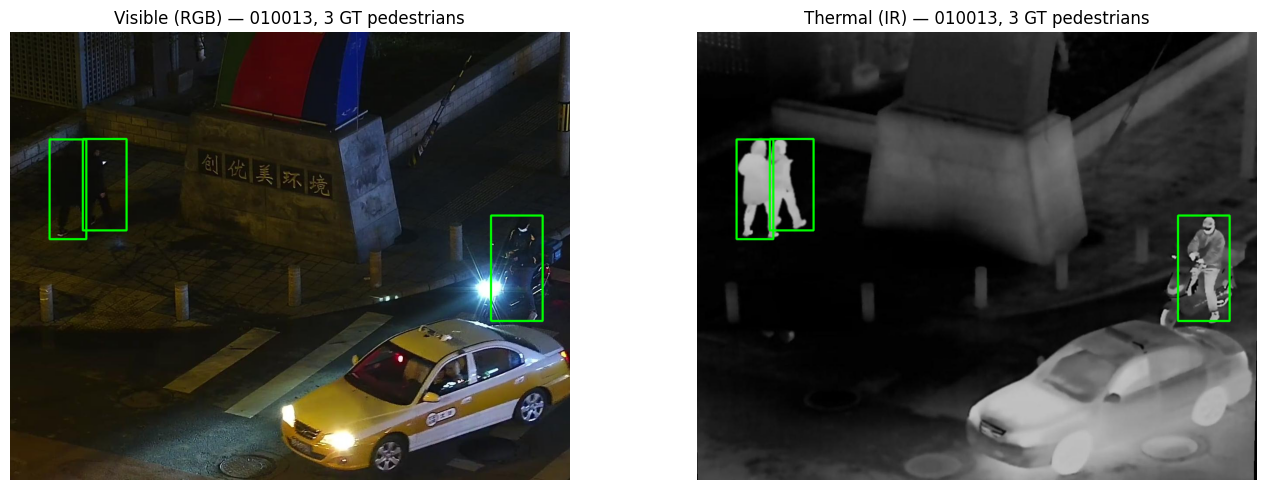

In [4]:
# Quick look at one pair (visible | thermal) with ground truth.
stem, rgb_p, ir_p, xml_p = TRAIN_PAIRS[12]
img_v = cv2.cvtColor(cv2.imread(str(rgb_p)), cv2.COLOR_BGR2RGB)
img_t = cv2.cvtColor(cv2.imread(str(ir_p)), cv2.COLOR_BGR2RGB)
gt_demo = read_voc(xml_p)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, im, title in zip(axes, (img_v, img_t), ("Visible (RGB)", "Thermal (IR)")):
    vis = im.copy()
    for b in gt_demo:
        cv2.rectangle(vis, tuple(int(v) for v in b[:2]), tuple(int(v) for v in b[2:]), (0, 255, 0), 3)
    ax.imshow(vis); ax.set_title(f"{title} — {stem}, {len(gt_demo)} GT pedestrians"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Frozen detectors (§3.1)
Two independent COCO-pretrained detectors (class 0 = person), with the RGB and thermal weights set **separately** by `CFG.rgb_weights` / `CFG.ir_weights`. **All parameters are frozen**; only the risk head is trained. Weights are never fine-tuned: the study's premise is that the detectors stay as released.

**Reporting the weights (put this in the paper, not the weight files):** file name, Ultralytics version, source/release, input size, confidence cut-offs, SHA-256. All of these are written to `run_summary.json`. **Licence:** Ultralytics code and weights are AGPL-3.0; check that against how the code release is licensed before publishing. Do not commit weight files to the paper; the code release should fetch them (or list the hashes).


In [5]:
from ultralytics import YOLO

import ultralytics

rgb_detector = YOLO(CFG.rgb_weights)
ir_detector = YOLO(CFG.ir_weights)
DETECTOR_PROVENANCE = {"ultralytics": ultralytics.__version__, "imgsz": CFG.imgsz,
                       "train_conf": CFG.train_conf, "test_conf": CFG.test_conf}
for side, det, wname in (("rgb", rgb_detector, CFG.rgb_weights), ("ir", ir_detector, CFG.ir_weights)):
    det.model.eval().to(device)
    n_frozen = 0
    for p in det.model.parameters():
        p.requires_grad = False
        n_frozen += p.numel()
    DETECTOR_PROVENANCE[side] = {"weights": wname, "frozen_parameters": n_frozen,
                                 "checkpoint_path": str(getattr(det, "ckpt_path", wname))}
    print(f"{side.upper():4s} {wname:14s}: {n_frozen:,} frozen parameters (requires_grad=False)")
print("Ultralytics", ultralytics.__version__, "| the weights are downloaded by Ultralytics on first use; their hashes are recorded in section 15.")


def run_detector(model, image_bgr: np.ndarray, conf: float) -> List[Tuple[np.ndarray, float]]:
    # Person detections as [(xyxy box, confidence), ...].
    r = model.predict(image_bgr, imgsz=CFG.imgsz, conf=conf, classes=[0], verbose=False, save=False)[0]
    if r.boxes is None or len(r.boxes) == 0:
        return []
    boxes = r.boxes.xyxy.cpu().numpy().astype(np.float32)
    scores = r.boxes.conf.cpu().numpy().astype(np.float32)
    return [(b, float(s)) for b, s in zip(boxes, scores)]

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
RGB  yolov8n.pt    : 3,157,200 frozen parameters (requires_grad=False)
IR   yolov8n.pt    : 3,157,200 frozen parameters (requires_grad=False)
Ultralytics 8.4.177 | the weights are downloaded by Ultralytics on first use; their hashes are recorded in section 15.


## 4. Cross-modal candidate generation (§3.6, eqs. 14–15, Algorithm 1 steps 2–4)

For an RGB box *i* and an infrared box *j*:

* `d_ij` = Euclidean distance between box centers ÷ RGB box diagonal (floor of 1 px)
* edge retained if `IoU_ij ≥ θ_assoc (0.05)` **or** `d_ij ≤ d_max (1.5)`
* edge score `s_ij = IoU_ij − 0.01·d_ij`
* edges sorted by `s_ij` and accepted **greedily, one-to-one**

Unmatched detections are preserved as single-modality candidates. This is a within-frame heuristic, **not** temporal tracking, and a permissive distance gate can pair nearby but distinct pedestrians in crowds (§3.6).

In [6]:
def calculate_iou(a: np.ndarray, b: np.ndarray) -> float:
    xa, ya = max(float(a[0]), float(b[0])), max(float(a[1]), float(b[1]))
    xb, yb = min(float(a[2]), float(b[2])), min(float(a[3]), float(b[3]))
    inter = max(0.0, xb - xa) * max(0.0, yb - ya)
    area_a = max(0.0, float(a[2] - a[0])) * max(0.0, float(a[3] - a[1]))
    area_b = max(0.0, float(b[2] - b[0])) * max(0.0, float(b[3] - b[1]))
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def center_dist_over_diag(b_rgb: np.ndarray, b_ir: np.ndarray) -> float:
    cr = ((b_rgb[0] + b_rgb[2]) / 2.0, (b_rgb[1] + b_rgb[3]) / 2.0)
    ci = ((b_ir[0] + b_ir[2]) / 2.0, (b_ir[1] + b_ir[3]) / 2.0)
    diag = max(math.hypot(float(b_rgb[2] - b_rgb[0]), float(b_rgb[3] - b_rgb[1])), 1.0)
    return math.hypot(cr[0] - ci[0], cr[1] - ci[1]) / diag


def associate(rgb_dets, ir_dets) -> List[dict]:
    # Returns candidates: dicts with keys b_rgb, c_rgb, b_ir, c_ir (missing modality -> None / 0.0).
    edges = []
    for i, (b_r, _) in enumerate(rgb_dets):
        for j, (b_i, _) in enumerate(ir_dets):
            iou, d = calculate_iou(b_r, b_i), center_dist_over_diag(b_r, b_i)
            if iou >= CFG.assoc_iou or d <= CFG.assoc_max_dist:
                edges.append((iou - 0.01 * d, i, j))
    edges.sort(key=lambda e: e[0], reverse=True)

    used_r, used_i, cands = set(), set(), []
    for _, i, j in edges:
        if i in used_r or j in used_i:
            continue
        used_r.add(i); used_i.add(j)
        cands.append({"b_rgb": rgb_dets[i][0], "c_rgb": rgb_dets[i][1], "b_ir": ir_dets[j][0], "c_ir": ir_dets[j][1]})
    for i, (b, c) in enumerate(rgb_dets):
        if i not in used_r:
            cands.append({"b_rgb": b, "c_rgb": c, "b_ir": None, "c_ir": 0.0})
    for j, (b, c) in enumerate(ir_dets):
        if j not in used_i:
            cands.append({"b_rgb": None, "c_rgb": 0.0, "b_ir": b, "c_ir": c})
    return cands


def is_matched(c: dict) -> bool:
    return c["b_rgb"] is not None and c["b_ir"] is not None

## 5. Candidate features (§3.2, eqs. 1–4, Table 2)

The canonical vector and the **exact order expected by the checkpoint** are

`[c_rgb, c_ir, |c_rgb − c_ir|, matched, IoU_ri, d_img, log(A_rgb/A_ir), |(h/w)_rgb − (h/w)_ir|]`

Missing-modality inputs: confidence 0, IoU 0, center distance 1, log-area ratio 0, aspect difference 0, matched flag 0.
The vector is standardized with the training-set mean/std (stored in the checkpoint); with no statistics the loader uses zero mean and unit scale.

In [7]:
FEATURE_NAMES = ["c_rgb", "c_ir", "abs_conf_diff", "matched_flag",
                 "box_iou", "center_dist", "log_area_ratio", "aspect_diff"]


def _wh(b):
    return max(0.0, float(b[2] - b[0])), max(0.0, float(b[3] - b[1]))


def extract_features(c: dict, img_w: int, img_h: int) -> np.ndarray:
    c_r = float(np.clip(c["c_rgb"], 0, 1)) if c["b_rgb"] is not None else 0.0
    c_i = float(np.clip(c["c_ir"], 0, 1)) if c["b_ir"] is not None else 0.0
    matched = 1.0 if is_matched(c) else 0.0

    if matched:
        b_r, b_i = c["b_rgb"], c["b_ir"]
        iou = calculate_iou(b_r, b_i)
        cr = np.array([(b_r[0] + b_r[2]) / 2 / img_w, (b_r[1] + b_r[3]) / 2 / img_h])
        ci = np.array([(b_i[0] + b_i[2]) / 2 / img_w, (b_i[1] + b_i[3]) / 2 / img_h])
        d_img = float(min(1.0, np.linalg.norm(cr - ci)))
        (wr, hr), (wi, hi) = _wh(b_r), _wh(b_i)
        log_area = math.log(max(wr * hr, 1.0) / max(wi * hi, 1.0))        # signed
        aspect = abs(hr / max(wr, 1.0) - hi / max(wi, 1.0))
    else:
        iou, d_img, log_area, aspect = 0.0, 1.0, 0.0, 0.0

    return np.array([c_r, c_i, abs(c_r - c_i), matched, iou, d_img, log_area, aspect], dtype=np.float32)


class Standardizer:
    def __init__(self, mean=None, std=None):
        self.mean = np.zeros(len(FEATURE_NAMES), np.float32) if mean is None else np.asarray(mean, np.float32)
        self.std = np.ones(len(FEATURE_NAMES), np.float32) if std is None else np.asarray(std, np.float32)

    def fit(self, X: np.ndarray):
        self.mean = X.mean(0).astype(np.float32)
        s = X.std(0).astype(np.float32)
        self.std = np.where(s < 1e-6, 1.0, s).astype(np.float32)
        return self

    def __call__(self, X: np.ndarray) -> np.ndarray:
        return ((X - self.mean) / self.std).astype(np.float32)


print("Feature order:", FEATURE_NAMES)

Feature order: ['c_rgb', 'c_ir', 'abs_conf_diff', 'matched_flag', 'box_iou', 'center_dist', 'log_area_ratio', 'aspect_diff']


## 6. Annotation-grounded counterfactual targets

For each candidate, the loss of each available action is computed against XML ground truth. If an action is unavailable for that candidate, its target loss is **1**, matching the inference availability mask. For an available action with box *b* and confidence *s*, let *q* be its maximum IoU with any annotation: a matched detection (*q ≥ 0.5*) gets loss `½[(1 − s)² + (1 − q)]`; an unmatched detection gets loss `s²`.

The joint action is defined as the late-average output: for a matched RGB/thermal pair it emits the RGB box with the mean of the two detector confidences. For an unmatched candidate, the joint action is unavailable. This exact joint box and score are used for target generation, the late-average baseline, and RAVEN inference. Thus the primary comparison uses the same candidate outputs and changes the action-selection policy; RAVEN may additionally abstain under its threshold policy.


In [8]:
ACTIONS = ["joint", "rgb", "ir"]


def action_loss(box: Optional[np.ndarray], conf: float, gt: np.ndarray) -> float:
    if box is None:
        return 1.0
    q = max([calculate_iou(box, g) for g in gt], default=0.0)
    if q >= 0.5:
        return float(0.5 * ((1.0 - conf) ** 2 + (1.0 - q)))
    return float(conf ** 2)


def action_box_conf(c: dict, action: str) -> Tuple[Optional[np.ndarray], float]:
    if action == "rgb":
        return c["b_rgb"], c["c_rgb"]
    if action == "ir":
        return c["b_ir"], c["c_ir"]
    # joint is the shared late-average action: RGB box, mean confidence.
    # It exists only for a matched pair; the availability mask uses the same rule.
    if is_matched(c):
        return c["b_rgb"], 0.5 * (c["c_rgb"] + c["c_ir"])
    return None, 0.0


def counterfactual_targets(c: dict, gt: np.ndarray) -> np.ndarray:
    return np.array([action_loss(*action_box_conf(c, a), gt) for a in ACTIONS], dtype=np.float32)


# Tiny self-check of eqs. (8)/(9) on a hand-made case.
_g = np.array([[10, 10, 50, 100]], np.float32)
_hit = {"b_rgb": np.array([10, 10, 50, 100], np.float32), "c_rgb": 0.9, "b_ir": None, "c_ir": 0.0}
assert abs(action_loss(_hit["b_rgb"], 0.9, _g) - 0.5 * ((1 - 0.9) ** 2 + 0.0)) < 1e-6
assert action_loss(None, 0.0, _g) == 1.0
print("Target rule self-check passed: unavailable joint action has loss 1.0.")

Target rule self-check passed: unavailable joint action has loss 1.0.


## 7. Risk head — S-DEC Config B (§3.3, eqs. 5–6, Tables 3–4)

`8 → 32 → 16 → 3`, ReLU, ReLU, **Sigmoid** (bounded, *not* calibrated). Abstention is a policy outcome, **not** a fourth network output.
Configs A (739 params) and C (931 params) are listed as architectural ablations only — the report contains no validation scores for them, so none are claimed here.

In [9]:
class PostHocRiskHead(nn.Module):
    def __init__(self, in_features: int = 8):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_features, 32), nn.ReLU(),
                                 nn.Linear(32, 16), nn.ReLU(),
                                 nn.Linear(16, 3), nn.Sigmoid())

    def forward(self, x):
        return self.net(x)


def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


print(f"{'Layer':<10}{'Mapping':<10}{'Weights':>9}{'Biases':>8}{'Total':>8}")
for name, (i, o) in {"Linear 1": (8, 32), "Linear 2": (32, 16), "Linear 3": (16, 3)}.items():
    print(f"{name:<10}{f'{i}->{o}':<10}{i * o:>9}{o:>8}{i * o + o:>8}")
for cfg_name, dim in (("Config A", 4), ("Config B (proposed)", 8), ("Config C", 10)):
    print(f"{cfg_name:<22} input={dim:<3} trainable parameters = {n_params(PostHocRiskHead(dim))}")

assert n_params(PostHocRiskHead(8)) == PAPER_REF["head_params_config_b"] == 867
print("\nConfig B parameter count matches the paper (867 = 816 weights + 51 biases).")

Layer     Mapping     Weights  Biases   Total
Linear 1  8->32           256      32     288
Linear 2  32->16          512      16     528
Linear 3  16->3            48       3      51
Config A               input=4   trainable parameters = 739
Config B (proposed)    input=8   trainable parameters = 867
Config C               input=10  trainable parameters = 931

Config B parameter count matches the paper (867 = 816 weights + 51 biases).


## 8. Head training on real LLVIP candidates (§3.9, §4.1, Table 6a, Fig. 2)

* Candidates come from every 64th pair of the official `train` split; the **first 150 pairs that contain ground truth** are kept. Detector threshold 0.10.
* The split is **by image**: the first 120 images (431 candidates) train the head and the last 30 images (75 candidates) validate it. No image contributes rows to both sets.
* Adam, lr 1e-3, weight decay 1e-4, batch 32, seed 42, MSE over the three action risks, 40 epochs (eqs. 10–11).

The validation MSE measures **loss convergence on candidate rows only** — not detection AP, calibration, or generalization. The checkpoint with the lowest validation MSE is kept, as in the original run (so the reported best validation value is mildly optimistic).

In [10]:
def collect(pairs, conf: float, n_max: Optional[int] = None, require_gt: bool = False, log_every: int = 25):
    records = []
    for stem, rgb_p, ir_p, xml_p in pairs:
        gt = read_voc(xml_p)
        if require_gt and len(gt) == 0:
            continue
        bgr, thr = cv2.imread(str(rgb_p)), cv2.imread(str(ir_p))
        if bgr is None or thr is None:
            continue
        h, w = bgr.shape[:2]
        cands = associate(run_detector(rgb_detector, bgr, conf), run_detector(ir_detector, thr, conf))
        records.append({"stem": stem, "w": w, "h": h, "gt": gt, "cands": cands})
        if len(records) % log_every == 0:
            print(f"  {len(records)} pairs | {sum(len(r['cands']) for r in records)} candidates")
        if n_max is not None and len(records) >= n_max:
            break
    return records


print("Extracting training candidates with frozen detectors...")
# Evenly spaced pairs across the WHOLE official train split (not the first N consecutive frames), so the
# head sees many different scenes. Oversample slightly, then keep the first N pairs that have ground truth.
stride = max(1, len(TRAIN_PAIRS) // int(CFG.num_train_pairs * 1.25))
train_subset = TRAIN_PAIRS[::stride]
train_records = collect(train_subset, CFG.train_conf, n_max=CFG.num_train_pairs, require_gt=True)
print(f"Training pairs: {len(train_records)} (every {stride}th of {len(TRAIN_PAIRS):,} official train pairs)")

X_all, Y_all, R_idx = [], [], []
for r_i, rec in enumerate(train_records):
    for c in rec["cands"]:
        X_all.append(extract_features(c, rec["w"], rec["h"]))
        Y_all.append(counterfactual_targets(c, rec["gt"]))
        R_idx.append(r_i)
X_all, Y_all, R_idx = np.stack(X_all), np.stack(Y_all), np.array(R_idx)

# IMAGE-wise split: the last (1 - train_frac) of the images form the validation set, so no image
# contributes rows to both sets and validation frames are not neighbours of training frames.
n_train_images = int(CFG.train_frac * len(train_records))
is_train = R_idx < n_train_images
X_tr, X_va, Y_tr, Y_va = X_all[is_train], X_all[~is_train], Y_all[is_train], Y_all[~is_train]
standardizer = Standardizer().fit(X_tr)
print(f"\nCandidates: {len(X_all)} total | {len(X_tr)} train | {len(X_va)} validation")

Extracting training candidates with frozen detectors...
  25 pairs | 80 candidates
  50 pairs | 249 candidates
  75 pairs | 319 candidates
  100 pairs | 391 candidates
  125 pairs | 442 candidates
  150 pairs | 506 candidates
Training pairs: 150 (every 64th of 12,025 official train pairs)

Candidates: 506 total | 431 train | 75 validation


In [11]:
def train_risk_head(X_tr, Y_tr, X_va, Y_va, in_features=8):
    set_seed(CFG.seed)
    model = PostHocRiskHead(in_features).to(device)
    opt = torch.optim.Adam(
        model.parameters(),
        lr=CFG.lr,
        weight_decay=CFG.weight_decay,
    )
    crit = nn.MSELoss()

    loader = DataLoader(
        TensorDataset(torch.tensor(X_tr), torch.tensor(Y_tr)),
        batch_size=CFG.batch_size,
        shuffle=True,
    )
    vx = torch.tensor(X_va).to(device)
    vy = torch.tensor(Y_va).to(device)

    tr_hist, va_hist = [], []
    best, best_state = float("inf"), None

    print(f"{'Epoch':^7}|{'Train MSE':^14}|{'Val MSE':^14}|")

    for ep in range(1, CFG.epochs + 1):
        model.train()
        total_loss = 0.0
        n_samples = 0

        for bx, by in loader:
            bx = bx.to(device)
            by = by.to(device)

            opt.zero_grad()
            loss = crit(model(bx), by)
            loss.backward()
            opt.step()

            total_loss += loss.item() * len(bx)
            n_samples += len(bx)

        model.eval()
        with torch.no_grad():
            val_loss = crit(model(vx), vy).item()

        train_loss = total_loss / max(n_samples, 1)
        tr_hist.append(train_loss)
        va_hist.append(val_loss)

        if val_loss < best:
            best = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        if ep in (1, 5, 10, 20, 30, 40) or ep == CFG.epochs:
            print(f"{ep:^7d}|{train_loss:^14.6f}|{val_loss:^14.6f}|")

    model.load_state_dict(best_state)
    print(f"\nBest validation MSE: {best:.6f}")

    return model.eval(), tr_hist, va_hist


head, train_hist, val_hist = train_risk_head(
    standardizer(X_tr),
    Y_tr,
    standardizer(X_va),
    Y_va,
)

print(
    f"\nBest validation MSE: {min(val_hist):.6f} "
    "(candidate-level loss only; not detection performance)"
)

 Epoch |  Train MSE   |   Val MSE    |
   1   |   0.168252   |   0.170087   |
   5   |   0.114690   |   0.119376   |
  10   |   0.067163   |   0.075847   |
  20   |   0.028591   |   0.031969   |
  30   |   0.021455   |   0.023789   |
  40   |   0.019091   |   0.021796   |

Best validation MSE: 0.021796

Best validation MSE: 0.021796 (candidate-level loss only; not detection performance)


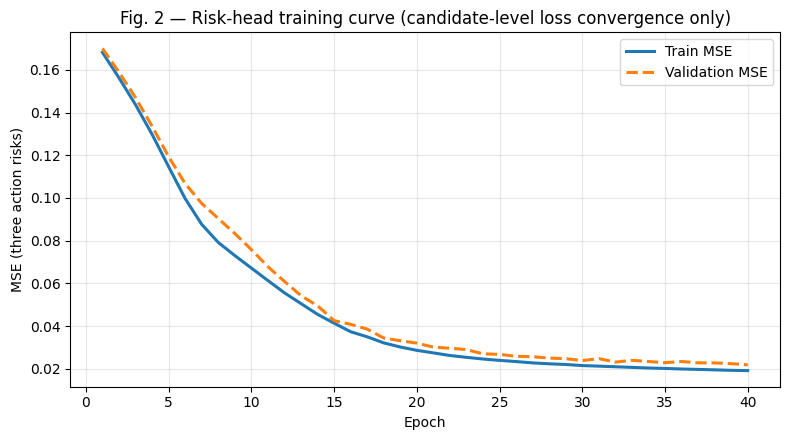

In [12]:
# Figure 2 (computed): training / validation MSE per epoch; logged checkpoints are marked.
fig, ax = plt.subplots(figsize=(8, 4.5))
ep = np.arange(1, len(train_hist) + 1)
ax.plot(ep, train_hist, color="#1f77b4", lw=2.2, label="Train MSE")
ax.plot(ep, val_hist, color="#ff7f0e", lw=2.2, ls="--", label="Validation MSE")
marks = []
ax.scatter(marks, [train_hist[e - 1] for e in marks], color="#1f77b4", zorder=3)
ax.scatter(marks, [val_hist[e - 1] for e in marks], color="#ff7f0e", zorder=3)
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (three action risks)")
ax.set_title("Fig. 2 — Risk-head training curve (candidate-level loss convergence only)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [13]:
CKPT_PATH = Path(CFG.out_dir) / "confidence_fusion.pt"
torch.save({"state_dict": {k: v.cpu() for k, v in head.state_dict().items()},
            "feature_names": FEATURE_NAMES,
            "mean": standardizer.mean, "std": standardizer.std,
            "tau": CFG.tau, "config": asdict(CFG)}, CKPT_PATH)
print("Checkpoint saved:", CKPT_PATH)

# To evaluate an EXISTING checkpoint instead of the one just trained, uncomment:
# ck = torch.load("/path/to/confidence_fusion.pt", map_location=device, weights_only=False)
# head.load_state_dict(ck["state_dict"]); head.eval()
# standardizer = Standardizer(ck.get("mean"), ck.get("std"))

Checkpoint saved: /content/raven_results/v8n_v8n/confidence_fusion.pt


## 9. Governance policy

For each candidate the head returns `[R_joint, R_rgb, R_ir]`. Availability exactly matches target construction: all three actions are available for a matched pair; only the existing sensor action is available for an unmatched detection. The joint action emits the RGB box with mean RGB/thermal confidence, matching the late-average baseline. RAVEN selects the lowest predicted risk among available actions; if that risk exceeds `tau`, it abstains and defers the candidate for human review.

The displayed scores are detector confidence values, not calibrated probabilities. `tau` is an experimental policy threshold and must not be described as a safety guarantee.


In [14]:
OUTCOME_NAMES = {"joint": "joint_consensus", "rgb": "ir_vetoed_rgb_dominant", "ir": "rgb_vetoed_thermal_dominant"}


@torch.no_grad()
def predict_risks(model, feats: np.ndarray) -> np.ndarray:
    if len(feats) == 0:
        return np.zeros((0, 3), np.float32)
    x = torch.tensor(standardizer(feats), dtype=torch.float32, device=device)
    return model(x).cpu().numpy()


def available_mask(c: dict) -> np.ndarray:
    if is_matched(c):
        return np.array([True, True, True])
    return np.array([False, c["b_rgb"] is not None, c["b_ir"] is not None])


# Explicit contract checks: target loss and inference availability must agree.
assert np.array_equal(available_mask(_hit), np.array([False, True, False]))
assert counterfactual_targets(_hit, _g)[0] == 1.0  # unavailable joint target
_pair = {"b_rgb": _g[0], "c_rgb": 0.8, "b_ir": _g[0].copy(), "c_ir": 0.6}
assert np.array_equal(available_mask(_pair), np.array([True, True, True]))
assert abs(action_box_conf(_pair, "joint")[1] - 0.7) < 1e-6  # same score used by late-average baseline


def govern(c: dict, risks: np.ndarray, tau: float = None) -> dict:
    tau = CFG.tau if tau is None else tau
    masked = np.where(available_mask(c), risks, np.inf)
    a = int(np.argmin(masked)); r_min = float(masked[a])
    if r_min > tau:
        return {"outcome": "abstain", "review": True, "action": None, "risk": r_min,
                "score": 100.0 * (1.0 - r_min), "box": None}
    action = ACTIONS[a]
    box, conf = action_box_conf(c, action)
    return {"outcome": OUTCOME_NAMES[action], "review": False, "action": action, "risk": r_min,
            "score": 100.0 * conf, "box": box}


def govern_image(cands: List[dict], img_w: int, img_h: int, tau: float = None) -> List[dict]:
    feats = np.stack([extract_features(c, img_w, img_h) for c in cands]) if cands else np.zeros((0, 8), np.float32)
    risks = predict_risks(head, feats)
    return [govern(c, r, tau) for c, r in zip(cands, risks)]


print("Policy ready: tau =", CFG.tau)

Policy ready: tau = 0.45



## 10. Image-disjoint LLVIP benchmark (§4.2, Table 7)

Every pair of the **official `test` split** is evaluated against the XML ground truth (3,463 pairs when `CFG.num_test_pairs = None`; set `CFG.num_test_pairs = 250` to reproduce the first-250-sorted subset used in the earlier draft). Four methods share the same test images, detector outputs, candidate generation, association, score filtering, ground-truth matching, and metric code:

* **RGB-only**, **Thermal-only**: emit that modality's boxes
* **Late Average Fusion**: choose the shared joint action (matched pair → RGB box with mean confidence; unmatched → the available sensor action)
* **RAVEN S-DEC**: choose among those same joint/RGB/thermal action outputs using the learned risk head; candidates above the abstention threshold are deferred

For matched candidates, the late-average output is exactly RAVEN's joint action. This makes the comparison a policy comparison over a shared candidate/action set. Abstention is a policy difference and can change coverage; report coverage alongside detection metrics.

**Metric definitions (as given in §4.2, eq. 17).**
*mAP@50* = Pascal-VOC all-point AP at IoU 0.50 over all detections with detector confidence ≥ 0.25. *Miss rate* = 1 − recall at that same operating point (share of ground-truth pedestrians not matched); it is **not** the log-average miss rate (LAMR) used in KAIST-style protocols. *FPPI* = false positives per image at the same operating point.

**Uncertainty.** An image-level bootstrap (below) treats every frame as independent, but LLVIP frames come from video, so neighbouring frames are near-duplicates and that interval is too narrow. §10.1 adds a **block bootstrap** over runs of consecutive frames, which is the more honest interval.


In [15]:
# Evaluate the requested subset, or the full official test split when the
# configuration sets CFG.num_test_pairs = None.
test_subset = (
    TEST_PAIRS
    if CFG.num_test_pairs is None
    else TEST_PAIRS[:CFG.num_test_pairs]
)

if not test_subset:
    raise RuntimeError("No LLVIP test pairs were selected.")

requested_stems = {stem for stem, *_ in test_subset}
train_stems = {stem for stem, *_ in train_records}
overlap = requested_stems & train_stems

if overlap:
    raise RuntimeError(
        f"Train/test leakage detected: {len(overlap)} shared image stems."
    )

limit_label = (
    "all official test pairs"
    if CFG.num_test_pairs is None
    else f"first {len(test_subset)} sorted official test pairs"
)
print(
    f"Running detectors on {limit_label} "
    f"({len(test_subset)} pairs; confidence={CFG.test_conf})..."
)

test_records = collect(
    test_subset,
    CFG.test_conf,
    n_max=None,       # Do not stop early; process every selected pair.
    require_gt=False,
    log_every=100,
)

loaded_stems = {record["stem"] for record in test_records}
missing_stems = requested_stems - loaded_stems

if missing_stems:
    examples = ", ".join(sorted(missing_stems)[:10])
    raise RuntimeError(
        f"Only loaded {len(test_records)} of {len(test_subset)} selected pairs. "
        f"Unreadable or missing examples: {examples}"
    )

print(
    f"Evaluated {len(test_records)} pairs; "
    f"train/test image stems are disjoint."
)

Running detectors on all official test pairs (3463 pairs; confidence=0.25)...
  100 pairs | 264 candidates
  200 pairs | 519 candidates
  300 pairs | 771 candidates
  400 pairs | 1008 candidates
  500 pairs | 1253 candidates
  600 pairs | 1513 candidates
  700 pairs | 1790 candidates
  800 pairs | 2039 candidates
  900 pairs | 2230 candidates
  1000 pairs | 2422 candidates
  1100 pairs | 2618 candidates
  1200 pairs | 2802 candidates
  1300 pairs | 3011 candidates
  1400 pairs | 3221 candidates
  1500 pairs | 3446 candidates
  1600 pairs | 3654 candidates
  1700 pairs | 3921 candidates
  1800 pairs | 4195 candidates
  1900 pairs | 4449 candidates
  2000 pairs | 4658 candidates
  2100 pairs | 4839 candidates
  2200 pairs | 5047 candidates
  2300 pairs | 5229 candidates
  2400 pairs | 5425 candidates
  2500 pairs | 5538 candidates
  2600 pairs | 5641 candidates
  2700 pairs | 5733 candidates
  2800 pairs | 5850 candidates
  2900 pairs | 5943 candidates
  3000 pairs | 6118 candidates
  31

In [16]:
def emit(policy: str, rec: dict, decisions: Optional[List[dict]] = None):
    # Detections [(box, score), ...] emitted by one policy for one image.
    out = []
    for k, c in enumerate(rec["cands"]):
        if policy == "rgb_only" and c["b_rgb"] is not None:
            out.append((c["b_rgb"], c["c_rgb"]))
        elif policy == "thermal_only" and c["b_ir"] is not None:
            out.append((c["b_ir"], c["c_ir"]))
        elif policy == "average_fusion":
            # Fixed baseline selects the shared joint action when available;
            # otherwise it selects the only available sensor action.
            action = "joint" if is_matched(c) else ("rgb" if c["b_rgb"] is not None else "ir")
            box, score = action_box_conf(c, action)
            out.append((box, score))
        elif policy == "raven":
            d = decisions[k]
            if not d["review"]:
                out.append((d["box"], d["score"] / 100.0))
    return out


def match_to_gt(dets, gt):
    # Greedy VOC matching at IoU>=0.5 in descending score order. Returns (scores, tp flags).
    dets = sorted(dets, key=lambda d: d[1], reverse=True)
    used, scores, tp = set(), [], []
    for box, s in dets:
        best, bi = 0.0, -1
        for gi, g in enumerate(gt):
            if gi in used:
                continue
            iou = calculate_iou(box, g)
            if iou > best:
                best, bi = iou, gi
        scores.append(s)
        if best >= 0.5:
            tp.append(1); used.add(bi)
        else:
            tp.append(0)
    return np.array(scores, np.float64), np.array(tp, np.int64)


def metrics_from(per_image: List[Tuple[np.ndarray, np.ndarray, int]]):
    n_img = len(per_image)
    n_gt = sum(n for _, _, n in per_image)
    scores = np.concatenate([s for s, _, _ in per_image]) if per_image else np.array([])
    tp = np.concatenate([t for _, t, _ in per_image]) if per_image else np.array([])
    if len(scores) == 0:
        return {"AP50": 0.0, "miss_rate": 1.0, "FPPI": 0.0}
    order = np.argsort(-scores, kind="stable")
    ctp, cfp = np.cumsum(tp[order]), np.cumsum(1 - tp[order])
    rec, prec = ctp / max(n_gt, 1), ctp / np.maximum(ctp + cfp, 1)
    rec, prec = np.r_[0.0, rec, 1.0], np.r_[0.0, prec, 0.0]
    for i in range(len(prec) - 2, -1, -1):
        prec[i] = max(prec[i], prec[i + 1])
    idx = np.where(rec[1:] != rec[:-1])[0]
    ap = float(np.sum((rec[idx + 1] - rec[idx]) * prec[idx + 1]))
    return {"AP50": ap, "miss_rate": (n_gt - int(tp.sum())) / max(n_gt, 1), "FPPI": int((1 - tp).sum()) / n_img}


POLICIES = [("rgb_only", "RGB-only (YOLOv8n)"), ("thermal_only", "Thermal-only (YOLOv8n)"),
            ("average_fusion", "Late Average Fusion"), ("raven", "RAVEN S-DEC (proposed)")]

test_decisions = [govern_image(r["cands"], r["w"], r["h"]) for r in test_records]
per_image = {p: [] for p, _ in POLICIES}
for rec, dec in zip(test_records, test_decisions):
    for p, _ in POLICIES:
        s, t = match_to_gt(emit(p, rec, dec), rec["gt"])
        per_image[p].append((s, t, len(rec["gt"])))

results = {p: metrics_from(per_image[p]) for p, _ in POLICIES}

print("=" * 100)
print("SINGLE-SEED PILOT ONLY — corrected LLVIP benchmark; final multi-seed results follow in Section 14")
print("=" * 100)
print(f"{'Method':<32}|{'mAP@50':>9}{'Miss':>9}{'FPPI':>9}")
for p, label in POLICIES:
    m = results[p]
    print(f"{label:<32}|{m['AP50']:>9.4f}{m['miss_rate']:>9.4f}{m['FPPI']:>9.4f}")
print("=" * 100)
d_ap = results["raven"]["AP50"] - results["average_fusion"]["AP50"]
print(f"RAVEN − shared-action late-average policy: ΔmAP@50 = {d_ap:+.4f}")

SINGLE-SEED PILOT ONLY — corrected LLVIP benchmark; final multi-seed results follow in Section 14
Method                          |   mAP@50     Miss     FPPI
RGB-only (YOLOv8n)              |   0.6300   0.3556   0.2143
Thermal-only (YOLOv8n)          |   0.5687   0.4238   0.1623
Late Average Fusion             |   0.6961   0.2844   0.3220
RAVEN S-DEC (proposed)          |   0.7056   0.2790   0.3090
RAVEN − shared-action late-average policy: ΔmAP@50 = +0.0095


In [17]:
# Supplementary: paired image-level bootstrap.
# The same resampled images are used for every method.
rng = np.random.default_rng(CFG.seed)
n = len(test_records)

if n == 0:
    raise RuntimeError("No test records available for bootstrap.")

boot = {
    p: {"AP50": [], "miss_rate": [], "FPPI": []}
    for p, _ in POLICIES
}

for _ in range(CFG.bootstrap_samples):
    idx = rng.integers(0, n, n)

    for p, _ in POLICIES:
        sampled_images = [per_image[p][i] for i in idx]
        metrics = metrics_from(sampled_images)

        for metric_name, value in metrics.items():
            boot[p][metric_name].append(value)


def ci(values):
    return np.percentile(values, [2.5, 97.5])


print(
    f"95% bootstrap intervals over {n:,} test images "
    f"({CFG.bootstrap_samples:,} resamples):"
)

for p, label in POLICIES:
    lo_ap, hi_ap = ci(boot[p]["AP50"])
    lo_miss, hi_miss = ci(boot[p]["miss_rate"])
    lo_fppi, hi_fppi = ci(boot[p]["FPPI"])

    print(
        f"  {label:<26} "
        f"mAP@50 [{lo_ap:.4f}, {hi_ap:.4f}]  "
        f"miss [{lo_miss:.4f}, {hi_miss:.4f}]  "
        f"FPPI [{lo_fppi:.4f}, {hi_fppi:.4f}]"
    )

# Paired difference: each bootstrap draw uses the same sampled images
# for RAVEN and Late Average Fusion.
paired_delta = (
    np.asarray(boot["raven"]["AP50"])
    - np.asarray(boot["average_fusion"]["AP50"])
)
delta_mean = float(paired_delta.mean())
delta_lo, delta_hi = ci(paired_delta)

print(
    f"\nPaired ΔmAP@50 (RAVEN − Late Average Fusion): "
    f"{delta_mean:+.4f}  95% CI [{delta_lo:+.4f}, {delta_hi:+.4f}]"
)

if delta_lo <= 0 <= delta_hi:
    print(
        f"The interval includes zero for this {n:,}-image test set. "
        "Results are from one dataset."
    )
else:
    print(
        f"The interval excludes zero for this {n:,}-image test set. "
        "Results are from one dataset and do not establish generalization "
        "to other datasets."
    )

95% bootstrap intervals over 3,463 test images (1,000 resamples):
  RGB-only (YOLOv8n)         mAP@50 [0.6173, 0.6428]  miss [0.3433, 0.3670]  FPPI [0.1984, 0.2319]
  Thermal-only (YOLOv8n)     mAP@50 [0.5566, 0.5820]  miss [0.4103, 0.4357]  FPPI [0.1496, 0.1767]
  Late Average Fusion        mAP@50 [0.6845, 0.7087]  miss [0.2729, 0.2955]  FPPI [0.3032, 0.3431]
  RAVEN S-DEC (proposed)     mAP@50 [0.6940, 0.7178]  miss [0.2675, 0.2899]  FPPI [0.2902, 0.3292]

Paired ΔmAP@50 (RAVEN − Late Average Fusion): +0.0095  95% CI [+0.0056, +0.0134]
The interval excludes zero for this 3,463-image test set. Results are from one dataset and do not establish generalization to other datasets.


### 10.1 Block bootstrap (consecutive-frame blocks)
Resamples blocks of `CFG.block_size` consecutive test files, assuming sorted filename order follows time. Verify that assumption from LLVIP metadata before interpreting this interval as a temporal block bootstrap; otherwise report it only as an ordering sensitivity analysis. The same blocks are used for both methods (paired).

In [18]:
def block_bootstrap_deltas(pol_a: str, pol_b: str):
    n = len(test_records)
    blocks = [list(range(s, min(s + CFG.block_size, n))) for s in range(0, n, CFG.block_size)]
    rng_b = np.random.default_rng(CFG.seed + 1)
    out_d = {"AP50": [], "miss_rate": [], "FPPI": []}
    for _ in range(CFG.bootstrap_samples):
        picked = rng_b.integers(0, len(blocks), len(blocks))
        idx = [j for b in picked for j in blocks[b]]
        ma = metrics_from([per_image[pol_a][j] for j in idx])
        mb = metrics_from([per_image[pol_b][j] for j in idx])
        for k in out_d:
            out_d[k].append(ma[k] - mb[k])
    return {k: np.asarray(v) for k, v in out_d.items()}


block_deltas = {}
bd = block_bootstrap_deltas("raven", "average_fusion")
print(f"Block bootstrap — {CFG.block_size}-frame blocks, {CFG.bootstrap_samples:,} resamples, "
      f"{len(test_records):,} test images. RAVEN minus Late Average Fusion:")
for k, label in (("AP50", "ΔmAP@50"), ("miss_rate", "Δmiss rate"), ("FPPI", "ΔFPPI")):
    lo, hi = np.percentile(bd[k], [2.5, 97.5])
    block_deltas[k] = {"mean": float(bd[k].mean()), "ci95": [float(lo), float(hi)]}
    verdict = "excludes 0" if (lo > 0 or hi < 0) else "includes 0"
    print(f"  {label:<11} {bd[k].mean():+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]   -> interval {verdict}")
print("(Lower is better for miss rate and FPPI. One dataset only; this does not establish generalization.)")

Block bootstrap — 50-frame blocks, 1,000 resamples, 3,463 test images. RAVEN minus Late Average Fusion:
  ΔmAP@50     +0.0093   95% CI [+0.0046, +0.0142]   -> interval excludes 0
  Δmiss rate  -0.0053   95% CI [-0.0086, -0.0020]   -> interval excludes 0
  ΔFPPI       -0.0127   95% CI [-0.0208, -0.0049]   -> interval excludes 0
(Lower is better for miss rate and FPPI. One dataset only; this does not establish generalization.)


### 10.2 Detection metrics under abstention (τ sweep)
The sweep in §13 (Table 10a) measured the head's own loss. Here the **detection metrics** are recomputed when RAVEN defers candidates: a deferred candidate is removed from the output, so **miss rate rises as deferral rises** and the benefit, if any, shows up as lower FPPI / higher precision.

Thresholds are chosen **on validation data, not on test data**: for each coverage target *c*, τ is the *c*-quantile of the validation candidates' minimum predicted risk. The fixed grid rows are descriptive only. With only 75 validation candidates these τ values are noisy and did not transfer to the test set (§4.3.1), so treat them as a starting point.

In [19]:
def candidate_min_risk_from_features(X: np.ndarray) -> np.ndarray:
    # Minimum predicted risk over the actions that are available for each candidate row.
    risks = predict_risks(head, X)
    matched = X[:, FEATURE_NAMES.index("matched_flag")] > 0.5
    has_rgb = X[:, FEATURE_NAMES.index("c_rgb")] > 0
    has_ir = X[:, FEATURE_NAMES.index("c_ir")] > 0
    avail = np.stack([matched, matched | has_rgb, matched | has_ir], axis=1)
    return np.where(avail, risks, np.inf).min(axis=1)


val_min_risk = candidate_min_risk_from_features(X_va)
tau_from_val = {f"val-cov{int(round(100 * c))}": float(np.quantile(val_min_risk, c))
                for c in CFG.val_coverage_targets}
print("tau from validation coverage targets:", {k: round(v, 4) for k, v in tau_from_val.items()},
      f"(from {len(val_min_risk)} validation candidates)")

# Cache risks once; the policy at each tau only re-thresholds them.
test_risks = [predict_risks(head, np.stack([extract_features(c, r["w"], r["h"]) for c in r["cands"]]))
              if r["cands"] else np.zeros((0, 3), np.float32) for r in test_records]


def raven_at_tau(tau: float):
    per_img, deferred, total = [], 0, 0
    for rec, risks in zip(test_records, test_risks):
        decs = [govern(c, rk, tau) for c, rk in zip(rec["cands"], risks)]
        deferred += sum(d["review"] for d in decs)
        total += len(decs)
        s, t = match_to_gt(emit("raven", rec, decs), rec["gt"])
        per_img.append((s, t, len(rec["gt"])))
    return metrics_from(per_img), deferred / max(total, 1)


rows_cfg = [("configured", CFG.tau)] + list(tau_from_val.items()) + \
           [(f"grid", t) for t in CFG.tau_grid if abs(t - CFG.tau) > 1e-9]
avg = results["average_fusion"]
print(f"\n{'Setting':<14}{'tau':>8}{'Deferred':>10}{'mAP@50':>9}{'Miss':>8}{'FPPI':>8}{'ΔmAP vs avg':>13}")
print(f"{'avg fusion':<14}{'-':>8}{'-':>10}{avg['AP50']:>9.4f}{avg['miss_rate']:>8.4f}{avg['FPPI']:>8.4f}{'-':>13}")
sweep_rows = []
for name, tau in rows_cfg:
    m, frac = raven_at_tau(tau)
    sweep_rows.append({"setting": name, "tau": float(tau), "deferred_fraction": float(frac), **m})
    print(f"{name:<14}{tau:>8.3f}{100 * frac:>9.1f}%{m['AP50']:>9.4f}{m['miss_rate']:>8.4f}{m['FPPI']:>8.4f}"
          f"{m['AP50'] - avg['AP50']:>+13.4f}")
print("\nRows named 'grid' are descriptive (looked at on test); only 'configured' and 'val-cov*' are defensible choices.")

tau from validation coverage targets: {'val-cov95': 0.3227, 'val-cov90': 0.3018, 'val-cov80': 0.2698} (from 75 validation candidates)

Setting            tau  Deferred   mAP@50    Miss    FPPI  ΔmAP vs avg
avg fusion           -         -   0.6961  0.2844  0.3220            -
configured       0.450      0.0%   0.7056  0.2790  0.3090      +0.0095
val-cov95        0.323      0.1%   0.7055  0.2791  0.3081      +0.0094
val-cov90        0.302      0.2%   0.7052  0.2795  0.3067      +0.0091
val-cov80        0.270      1.0%   0.7019  0.2832  0.2992      +0.0057
grid             0.350      0.0%   0.7056  0.2790  0.3090      +0.0095
grid             0.250      1.8%   0.6976  0.2879  0.2945      +0.0014
grid             0.200      7.4%   0.6649  0.3226  0.2631      -0.0312
grid             0.150     29.4%   0.5319  0.4605  0.1461      -0.1642

Rows named 'grid' are descriptive (looked at on test); only 'configured' and 'val-cov*' are defensible choices.


## 11. Head-only compute profile (§4.3, Table 8)

Analytical work: **816 MACs + 51 bias adds** per candidate (867 is the *parameter* count, not the MAC count). Timings use a neutral all-zero `[1, 8]` input, model and tensor resident on the device, and measure **only the head** — not the detectors, association, or an end-to-end frame rate. Results depend on the hardware of this runtime; the paper's numbers come from a laptop (i5-12500H, RTX 3050) and should not be expected to match Colab.

In [20]:
def profile_head_cpu(model, warmup=1000, iters=10000):
    m = PostHocRiskHead(8); m.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()}); m.eval()
    prev = torch.get_num_threads(); torch.set_num_threads(1)
    x = torch.zeros(1, 8)
    with torch.no_grad():
        for _ in range(warmup): m(x)
        t = np.empty(iters)
        for i in range(iters):
            t0 = time.perf_counter_ns(); m(x); t[i] = (time.perf_counter_ns() - t0) / 1e6
    torch.set_num_threads(prev)
    return {"mean_ms": float(t.mean()), "median_ms": float(np.median(t)), "p95_ms": float(np.percentile(t, 95))}


def profile_head_cuda(model, warmup=1000, iters=5000):
    if not torch.cuda.is_available():
        return None
    m = model.to("cuda").eval(); x = torch.zeros(1, 8, device="cuda"); times = []
    with torch.no_grad():
        for _ in range(warmup): m(x)
        torch.cuda.synchronize()
        for _ in range(iters):
            a, b = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            a.record(); m(x); b.record(); torch.cuda.synchronize(); times.append(a.elapsed_time(b))
    return {"mean_ms": float(np.mean(times))}


cpu_prof, cuda_prof = profile_head_cpu(head), profile_head_cuda(head)
head.to(device)
print(f"Analytical work   : 816 MAC + 51 bias adds (867 trainable parameters)")
print(f"Host CPU          : {platform.processor() or platform.machine()}  (1 PyTorch thread, 1,000 warm-up / 10,000 timed)")
print(f"  CPU latency     : mean {cpu_prof['mean_ms']:.3f} ms | median {cpu_prof['median_ms']:.3f} ms | p95 {cpu_prof['p95_ms']:.3f} ms")
if cuda_prof:
    print(f"GPU               : {torch.cuda.get_device_name(0)}  (CUDA events, 1,000 warm-up / 5,000 timed)")
    print(f"  CUDA latency    : mean {cuda_prof['mean_ms']:.3f} ms")
print("Detector / association / end-to-end latency and Jetson results: NOT measured here (as in the paper).")

Analytical work   : 816 MAC + 51 bias adds (867 trainable parameters)
Host CPU          : x86_64  (1 PyTorch thread, 1,000 warm-up / 10,000 timed)
  CPU latency     : mean 0.054 ms | median 0.045 ms | p95 0.090 ms
GPU               : Tesla T4  (CUDA events, 1,000 warm-up / 5,000 timed)
  CUDA latency    : mean 0.642 ms
Detector / association / end-to-end latency and Jetson results: NOT measured here (as in the paper).


## 12. Qualitative demonstration of the governance path (§3.8, §4.5)

This runs the real pipeline on one **held-out test pair**, optionally degrading the visible image (headlight glare, darkness, or defocus blur) to exercise the veto / abstain logic.

It is a **qualitative** illustration only. The paper's *Scene 08 (Headlight Glare)* and *Scene 01 (Low-Light Alley)* are live Streamlit-dashboard playbacks and are not reproduced here; no controlled ground-truth evaluation, per-scene metric, or generalization claim follows from this cell.

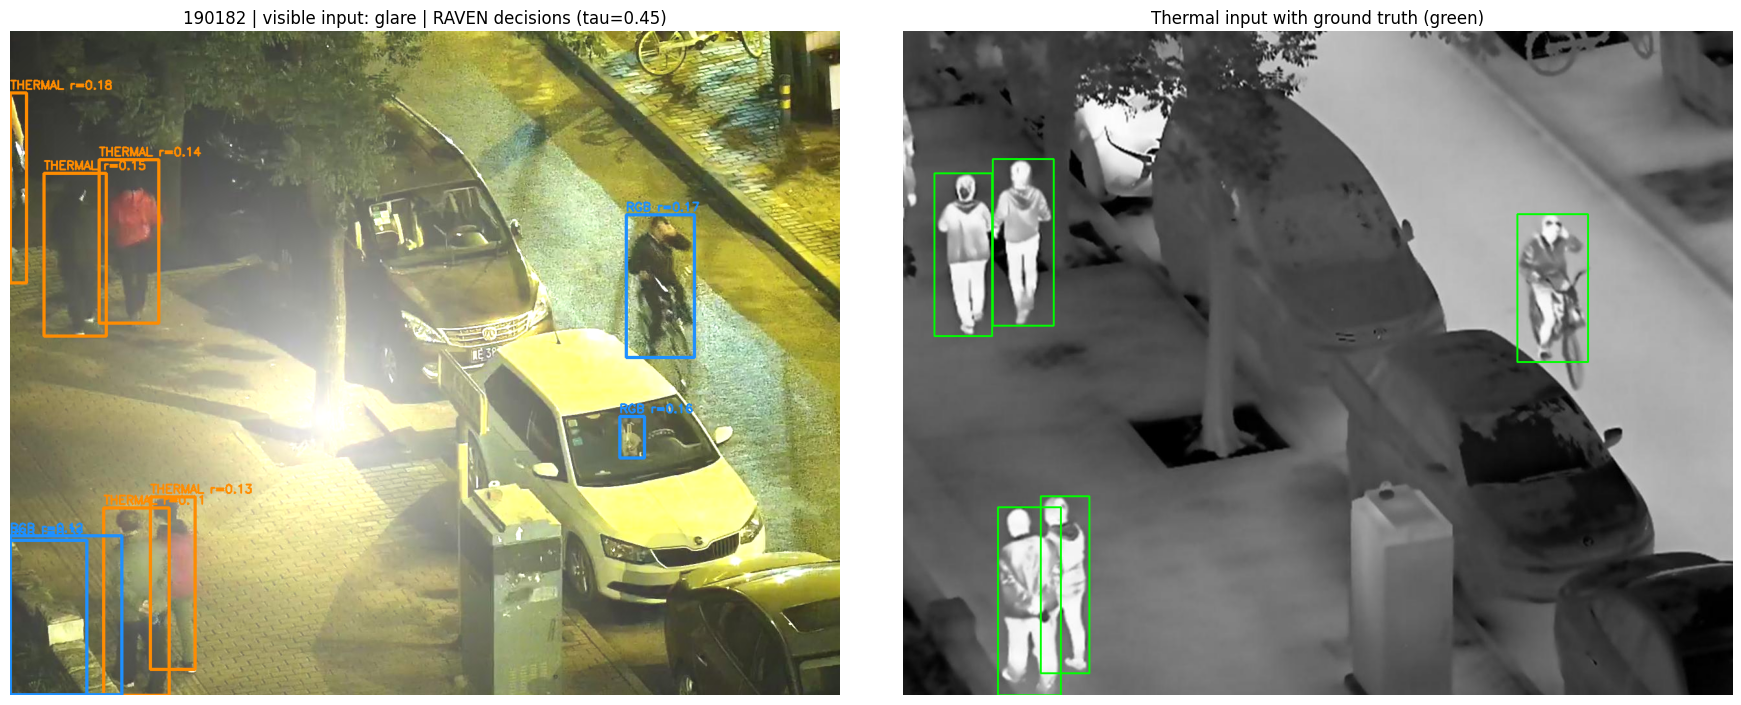

Outcome counts: {'rgb_vetoed_thermal_dominant': 5, 'ir_vetoed_rgb_dominant': 4}


In [21]:
class OpticalDegradationEngine:
    def __init__(self, seed: int = 42):
        self.rng = np.random.default_rng(seed)

    def apply_darkness(self, img, factor=0.20):
        return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)

    def apply_defocus_blur(self, img, ksize=19, sigma=6.0):
        return cv2.GaussianBlur(img, (ksize, ksize), sigma)

    def apply_headlight_glare(self, img):
        h, w = img.shape[:2]
        cx = self.rng.integers(int(w * 0.35), int(w * 0.65)); cy = self.rng.integers(int(h * 0.35), int(h * 0.65))
        yy, xx = np.ogrid[:h, :w]
        radius = self.rng.uniform(min(h, w) * 0.28, min(h, w) * 0.45)
        glare = np.exp(-np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2) / (radius + 1e-5)) * 255.0
        return np.clip(img.astype(np.float32) + glare[:, :, None], 0, 255).astype(np.uint8)


DEMO_INDEX = 180          # index into the sorted official test split
DEMO_CORRUPTION = "glare" # "glare" | "darkness" | "blur" | "none"

corruptor = OpticalDegradationEngine(CFG.seed)
stem, rgb_p, ir_p, xml_p = TEST_PAIRS[DEMO_INDEX]
bgr, thr, gt = cv2.imread(str(rgb_p)), cv2.imread(str(ir_p)), read_voc(xml_p)
bgr_in = {"glare": corruptor.apply_headlight_glare, "darkness": corruptor.apply_darkness,
          "blur": corruptor.apply_defocus_blur, "none": lambda x: x}[DEMO_CORRUPTION](bgr)

h, w = bgr_in.shape[:2]
cands = associate(run_detector(rgb_detector, bgr_in, 0.15), run_detector(ir_detector, thr, 0.15))
decisions = govern_image(cands, w, h)

COLORS = {"joint_consensus": (0, 200, 0), "ir_vetoed_rgb_dominant": (30, 144, 255),
          "rgb_vetoed_thermal_dominant": (255, 140, 0), "abstain": (220, 30, 30)}
SHORT = {"joint_consensus": "JOINT", "ir_vetoed_rgb_dominant": "RGB", "rgb_vetoed_thermal_dominant": "THERMAL", "abstain": "REVIEW"}

canvas = cv2.cvtColor(bgr_in, cv2.COLOR_BGR2RGB)
for c, d in zip(cands, decisions):
    box = d["box"] if d["box"] is not None else (c["b_ir"] if c["b_ir"] is not None else c["b_rgb"])
    col = COLORS[d["outcome"]]
    cv2.rectangle(canvas, tuple(int(v) for v in box[:2]), tuple(int(v) for v in box[2:]), col, 3)
    cv2.putText(canvas, f"{SHORT[d['outcome']]} r={d['risk']:.2f}", (int(box[0]), max(18, int(box[1]) - 6)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)

thermal_view = cv2.cvtColor(thr, cv2.COLOR_BGR2RGB).copy()
for g in gt:
    cv2.rectangle(thermal_view, tuple(int(v) for v in g[:2]), tuple(int(v) for v in g[2:]), (0, 255, 0), 2)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(canvas); axes[0].set_title(f"{stem} | visible input: {DEMO_CORRUPTION} | RAVEN decisions (tau={CFG.tau})"); axes[0].axis("off")
axes[1].imshow(thermal_view); axes[1].set_title("Thermal input with ground truth (green)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

from collections import Counter
print("Outcome counts:", dict(Counter(d["outcome"] for d in decisions)))

## 13. Supplementary: coverage vs. selective risk on test candidates (§4.3.2, eq. 20, Table 10a, Fig. 3)

The paper reports a risk-coverage table for the benchmark candidates in §4.3.2. This cell computes it: sweeping `τ`, *coverage* = fraction of candidates the policy answers, *selective risk* = mean annotation-grounded action loss (§6, eqs. 8–9) of the chosen action over the answered candidates.

These values are reported in §4.3.2. They measure candidate-level task loss — not detection AP, and not calibration — and the number of candidates is small.

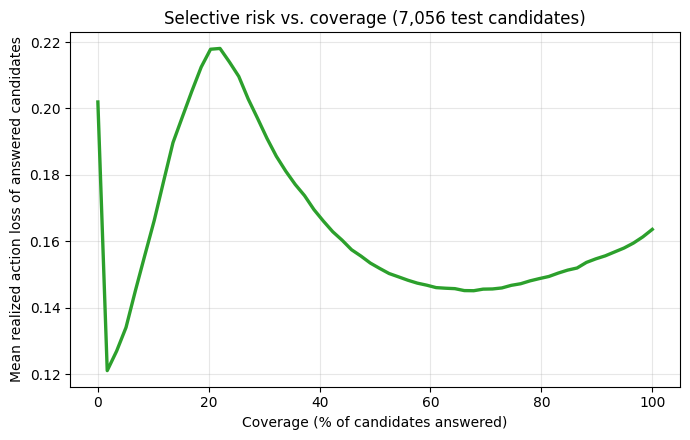


Test-set threshold sweep (descriptive; tune tau on validation data):
     Tau |   Coverage |   Deferred |   Mean answered loss
------------------------------------------------------------
    0.45 |     100.0% |          0 |               0.1636
    0.35 |     100.0% |          0 |               0.1636
    0.25 |      98.2% |        124 |               0.1613
    0.20 |      92.6% |        521 |               0.1562
    0.15 |      70.6% |      2,071 |               0.1455

Configured tau=0.45: 100.0% coverage; 0 candidates deferred.


In [22]:
# Descriptive test-set coverage sweep.
# Choose the final tau using validation data, not this test-set table.

rows = []

for rec in test_records:
    for c in rec["cands"]:
        feats = extract_features(c, rec["w"], rec["h"])[None, :]
        risks = predict_risks(head, feats)[0]

        # Exclude actions that are unavailable for this candidate.
        masked = np.where(available_mask(c), risks, np.inf)
        action_idx = int(np.argmin(masked))

        rows.append((
            float(masked[action_idx]),
            float(counterfactual_targets(c, rec["gt"])[action_idx]),
        ))

rows = np.asarray(rows, dtype=np.float64)

if len(rows) == 0:
    raise RuntimeError("No test candidates available for coverage analysis.")

min_risk = rows[:, 0]
selected_loss = rows[:, 1]

# Quantile thresholds create a smooth risk-coverage plot.
taus = np.unique(
    np.r_[0.0, np.quantile(min_risk, np.linspace(0, 1, 60)), 1.0]
)
coverage = np.array([(min_risk <= tau).mean() for tau in taus])
selective_risk = np.array([
    selected_loss[min_risk <= tau].mean()
    if (min_risk <= tau).any()
    else np.nan
    for tau in taus
])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(coverage * 100, selective_risk, lw=2.4, color="#2ca02c")
ax.set_xlabel("Coverage (% of candidates answered)")
ax.set_ylabel("Mean realized action loss of answered candidates")
ax.set_title(f"Selective risk vs. coverage ({len(rows):,} test candidates)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# These thresholds are descriptive only. Do not select tau from test results.
print("\nTest-set threshold sweep (descriptive; tune tau on validation data):")
print(f"{'Tau':>8} | {'Coverage':>10} | {'Deferred':>10} | {'Mean answered loss':>20}")
print("-" * 60)

for tau in [0.45, 0.35, 0.25, 0.20, 0.15]:
    answered = min_risk <= tau
    n_answered = int(answered.sum())
    n_deferred = len(rows) - n_answered
    coverage_pct = 100.0 * n_answered / len(rows)

    mean_loss = (
        f"{selected_loss[answered].mean():.4f}"
        if n_answered
        else "n/a"
    )

    print(
        f"{tau:>8.2f} | {coverage_pct:>9.1f}% | "
        f"{n_deferred:>10,} | {mean_loss:>20}"
    )

at_tau = min_risk <= CFG.tau
print(
    f"\nConfigured tau={CFG.tau:.2f}: "
    f"{at_tau.mean() * 100:.1f}% coverage; "
    f"{len(rows) - int(at_tau.sum()):,} candidates deferred."
)

## 14. LLVIP-only multi-seed and ablation evaluation

This section repeats risk-head training with three seeds while keeping the LLVIP train/validation/test images and detector candidate bank fixed. It compares the full eight-feature head with confidence-plus-match and confidence-only ablations. Every model uses the same available actions, late-average baseline, validation-selected 95% coverage threshold, test candidates, and metric code. This measures sensitivity to head initialization/minibatch order and feature choice; it does not test generalization beyond LLVIP.

The final tables report per-seed results, mean and standard deviation across seeds, paired image-bootstrap intervals for RAVEN minus late-average fusion, and per-image true-positive/false-positive/miss counts. The image bootstrap treats images as resampling units; adjacent LLVIP frames may be correlated, so treat those intervals as exploratory unless clip/scene grouping is verified.


In [23]:
# Repeat only the risk head: frozen-detector candidates and the image split are reused.
# Keep MODEL_SEEDS fixed before running; do not select the best seed.
MODEL_SEEDS = (42, 123, 2025)
ABLATIONS = {
    "full_8_features": [0, 1, 2, 3, 4, 5, 6, 7],
    "confidence_plus_match": [0, 1, 2, 3],
    "confidence_only": [0, 1],
}
ABLATION_FEATURE_NAMES = {
    "full_8_features": FEATURE_NAMES,
    "confidence_plus_match": FEATURE_NAMES[:4],
    "confidence_only": FEATURE_NAMES[:2],
}
TARGET_COVERAGE = 0.95  # threshold is selected from validation candidates only

# Raw features preserve the same order as X_all; split rows by source image as above.
X_train_raw, X_val_raw = X_all[is_train], X_all[~is_train]
Y_train, Y_val = Y_all[is_train], Y_all[~is_train]
assert len(X_train_raw) == len(Y_train) and len(X_val_raw) == len(Y_val)


def fit_ablation_head(Xtr_raw, Ytr, Xv_raw, Yv, feature_idx, seed):
    """Train one risk head; fit normalization on train rows only."""
    set_seed(seed)
    Xtr, Xv = Xtr_raw[:, feature_idx], Xv_raw[:, feature_idx]
    mean = Xtr.mean(0).astype(np.float32)
    std = Xtr.std(0).astype(np.float32)
    std[std < 1e-6] = 1.0
    Xtr = ((Xtr - mean) / std).astype(np.float32)
    Xv = ((Xv - mean) / std).astype(np.float32)

    model = PostHocRiskHead(len(feature_idx)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(Ytr)),
                        batch_size=CFG.batch_size, shuffle=True)
    vx, vy = torch.tensor(Xv, device=device), torch.tensor(Yv, device=device)
    best, best_state, train_hist, val_hist = float("inf"), None, [], []
    for epoch in range(CFG.epochs):
        model.train(); total = count = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = nn.functional.mse_loss(model(xb), yb)
            loss.backward(); opt.step()
            total += loss.item() * len(xb); count += len(xb)
        model.eval()
        with torch.no_grad(): val_loss = nn.functional.mse_loss(model(vx), vy).item()
        train_hist.append(total / max(count, 1)); val_hist.append(val_loss)
        if val_loss < best:
            best = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    return {"model": model, "feature_idx": list(feature_idx), "mean": mean, "std": std,
            "best_val_mse": float(best), "train_hist": train_hist, "val_hist": val_hist,
            "seed": int(seed)}


def model_predict(package, Xraw):
    if len(Xraw) == 0:
        return np.zeros((0, 3), dtype=np.float32)
    idx = package["feature_idx"]
    z = ((Xraw[:, idx] - package["mean"]) / package["std"]).astype(np.float32)
    with torch.no_grad():
        return package["model"](torch.tensor(z, device=device)).cpu().numpy()


def availability_from_raw(Xraw):
    matched = Xraw[:, FEATURE_NAMES.index("matched_flag")] > 0.5
    has_rgb = Xraw[:, FEATURE_NAMES.index("c_rgb")] > 0
    has_ir = Xraw[:, FEATURE_NAMES.index("c_ir")] > 0
    return np.stack([matched, matched | has_rgb, matched | has_ir], axis=1)


def validation_tau(package):
    risks = model_predict(package, X_val_raw)
    avail = availability_from_raw(X_val_raw)
    min_risk = np.where(avail, risks, np.inf).min(axis=1)
    return float(np.quantile(min_risk, TARGET_COVERAGE, method="higher"))


def evaluate_package(package, tau, keep_per_image=False):
    per_image, error_rows = [], []
    deferred = total_candidates = 0
    for rec in test_records:
        raw = np.stack([extract_features(c, rec["w"], rec["h"]) for c in rec["cands"]]) if rec["cands"] else np.zeros((0, 8), np.float32)
        risks = model_predict(package, raw)
        emitted = []
        deferred_image = 0
        for cand, x, risk in zip(rec["cands"], raw, risks):
            avail = availability_from_raw(x[None, :])[0]
            masked = np.where(avail, risk, np.inf)
            action_idx = int(np.argmin(masked)); best_risk = float(masked[action_idx])
            if best_risk > tau:
                deferred += 1; deferred_image += 1
                continue
            action = ACTIONS[action_idx]
            box, score = action_box_conf(cand, action)
            if box is not None:
                emitted.append((box, float(score)))
        total_candidates += len(rec["cands"])
        scores, tp = match_to_gt(emitted, rec["gt"])
        per_image.append((scores, tp, len(rec["gt"])))
        error_rows.append({"image_stem": rec["stem"], "ground_truth": len(rec["gt"]),
                           "true_positives": int(tp.sum()), "false_positives": int((1 - tp).sum()),
                           "misses": int(len(rec["gt"]) - tp.sum()),
                           "candidate_count": len(rec["cands"]), "deferred": deferred_image})
    metrics = metrics_from(per_image)
    metrics["coverage"] = 1.0 - deferred / max(total_candidates, 1)
    metrics["deferred_fraction"] = deferred / max(total_candidates, 1)
    metrics["TP"] = int(sum(int(t.sum()) for _, t, _ in per_image))
    metrics["FP"] = int(sum(int((1 - t).sum()) for _, t, _ in per_image))
    metrics["FN"] = int(sum(n - int(t.sum()) for _, t, n in per_image))
    if keep_per_image:
        return metrics, per_image, error_rows
    return metrics


robust_runs = {}
robust_rows = []
error_rows_all = []
robust_training_log = []
for ablation_name, feature_idx in ABLATIONS.items():
    for seed in MODEL_SEEDS:
        print(f"Training {ablation_name}, seed={seed} ...")
        package = fit_ablation_head(X_train_raw, Y_train, X_val_raw, Y_val, feature_idx, seed)
        tau = validation_tau(package)
        metrics, per_image, errors = evaluate_package(package, tau, keep_per_image=True)
        run_key = (ablation_name, seed)
        robust_runs[run_key] = {"package": package, "tau": tau, "metrics": metrics,
                                "per_image": per_image, "errors": errors}
        robust_rows.append({"ablation": ablation_name, "seed": seed, "tau_val_95cov": tau,
                            "best_val_mse": package["best_val_mse"], **metrics})
        for epoch, (train_loss, val_loss) in enumerate(zip(package["train_hist"], package["val_hist"]), 1):
            robust_training_log.append({"ablation": ablation_name, "seed": seed, "epoch": epoch,
                                        "train_mse": train_loss, "val_mse": val_loss})
        ckpt_dir = Path(CFG.out_dir) / "multi_seed_checkpoints"
        ckpt_dir.mkdir(parents=True, exist_ok=True)
        torch.save({"state_dict": {k: v.cpu() for k, v in package["model"].state_dict().items()},
                    "features": ABLATION_FEATURE_NAMES[ablation_name],
                    "feature_indices": feature_idx, "mean": package["mean"].tolist(),
                    "std": package["std"].tolist(), "seed": seed, "tau_validation_95cov": tau,
                    "best_validation_mse": package["best_val_mse"]},
                   ckpt_dir / f"{ablation_name}_seed{seed}.pt")
        for row in errors:
            row.update({"method": "RAVEN", "ablation": ablation_name, "seed": seed})
            error_rows_all.append(row)

print("Completed", len(robust_rows), "LLVIP risk-head runs.")


Training full_8_features, seed=42 ...
Training full_8_features, seed=123 ...
Training full_8_features, seed=2025 ...
Training confidence_plus_match, seed=42 ...
Training confidence_plus_match, seed=123 ...
Training confidence_plus_match, seed=2025 ...
Training confidence_only, seed=42 ...
Training confidence_only, seed=123 ...
Training confidence_only, seed=2025 ...
Completed 9 LLVIP risk-head runs.


In [24]:
# Summarize seed variation and ablation effects; baseline is identical across all runs.
import csv

baseline = results["average_fusion"]

print("\nPer-run results (threshold selected on validation for 95% nominal coverage)")
print(
    f"{'Ablation':<26} {'Seed':>6} {'mAP50':>8} {'Miss':>8} "
    f"{'FPPI':>8} {'Coverage':>9} {'FP':>8} {'FN':>8} {'ΔAP50':>8}"
)

for row in robust_rows:
    delta = row["AP50"] - baseline["AP50"]
    row["delta_AP50_vs_late_average"] = delta

    print(
        f"{row['ablation']:<26} {row['seed']:>6} "
        f"{row['AP50']:>8.4f} {row['miss_rate']:>8.4f} "
        f"{row['FPPI']:>8.4f} {row['coverage']:>8.1%} "
        f"{row['FP']:>8d} {row['FN']:>8d} {delta:>+8.4f}"
    )


print("\nAcross-seed mean ± SD (descriptive; do not select the best seed)")

for name in ABLATIONS:
    rows = [row for row in robust_rows if row["ablation"] == name]

    summary = " | ".join(
        f"{metric} "
        f"{np.mean([row[metric] for row in rows]):.4f} ± "
        f"{np.std([row[metric] for row in rows], ddof=1):.4f}"
        for metric in ("AP50", "miss_rate", "FPPI", "coverage")
    )

    print(name, "|", summary)


# Rebuild late-average results for each test image.
# A dedicated variable avoids conflicts with other notebook cells named per_image.
baseline_per_image = []

for rec in test_records:
    baseline_detections = emit("average_fusion", rec)
    baseline_scores, baseline_tp = match_to_gt(
        baseline_detections,
        rec["gt"],
    )
    baseline_per_image.append(
        (baseline_scores, baseline_tp, len(rec["gt"]))
    )


# Paired image bootstrap for full-feature RAVEN versus late-average fusion.
# Each replicate uses the same sampled images for both methods.
rng_ci = np.random.default_rng(CFG.seed + 917)
n_test = len(test_records)

if n_test == 0:
    raise RuntimeError(
        "No test records available for the paired bootstrap."
    )

boot_delta_ap = []

for seed in MODEL_SEEDS:
    raven_per_image = robust_runs[
        ("full_8_features", seed)
    ]["per_image"]

    for _ in range(CFG.bootstrap_samples):
        indices = rng_ci.integers(0, n_test, n_test)

        raven_metrics = metrics_from(
            [raven_per_image[i] for i in indices]
        )
        baseline_metrics = metrics_from(
            [baseline_per_image[i] for i in indices]
        )

        boot_delta_ap.append(
            raven_metrics["AP50"] - baseline_metrics["AP50"]
        )

ci_lo, ci_hi = np.percentile(boot_delta_ap, [2.5, 97.5])

mean_delta = float(
    np.mean([
        row["AP50"] - baseline["AP50"]
        for row in robust_rows
        if row["ablation"] == "full_8_features"
    ])
)

print(
    f"\nFull-feature mean paired ΔmAP50 vs late-average: "
    f"{mean_delta:+.4f}; pooled paired image-bootstrap 95% interval "
    f"[{ci_lo:+.4f}, {ci_hi:+.4f}]"
)
print(
    "Interpret image-bootstrap intervals cautiously: LLVIP frames may be "
    "temporally correlated; verify clip/scene grouping before inferential claims."
)


# Add late-average baseline counts to the per-image error analysis.
for rec, (scores, tp, n_gt) in zip(test_records, baseline_per_image):
    error_rows_all.append({
        "method": "Late Average Fusion",
        "ablation": "fixed_baseline",
        "seed": "shared",
        "image_stem": rec["stem"],
        "ground_truth": int(n_gt),
        "true_positives": int(tp.sum()),
        "false_positives": int((1 - tp).sum()),
        "misses": int(n_gt - tp.sum()),
        "candidate_count": len(rec["cands"]),
        "deferred": 0,
    })


# Save run-level metrics and per-image error counts.
out = Path(CFG.out_dir)

with (out / "multi_seed_ablation_metrics.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(robust_rows[0].keys()),
    )
    writer.writeheader()
    writer.writerows(robust_rows)

with (out / "error_analysis_by_image.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    fields = [
        "method",
        "ablation",
        "seed",
        "image_stem",
        "ground_truth",
        "true_positives",
        "false_positives",
        "misses",
        "candidate_count",
        "deferred",
    ]
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(error_rows_all)

with (out / "multi_seed_training_log.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    fields = ["ablation", "seed", "epoch", "train_mse", "val_mse"]
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(robust_training_log)


# Store the bootstrap interval for the reproducibility summary.
robust_bootstrap_summary = {
    "metric": "paired_delta_mAP50_full_features_minus_late_average",
    "mean_seed_delta": mean_delta,
    "image_bootstrap_ci95": [float(ci_lo), float(ci_hi)],
    "resamples_per_seed": CFG.bootstrap_samples,
    "unit": "test image; temporal correlation may remain",
}

print(
    "Saved multi_seed_ablation_metrics.csv, "
    "multi_seed_training_log.csv, and error_analysis_by_image.csv under",
    out,
)


Per-run results (threshold selected on validation for 95% nominal coverage)
Ablation                     Seed    mAP50     Miss     FPPI  Coverage       FP       FN    ΔAP50
full_8_features                42   0.7055   0.2791   0.3084   100.0%     1068     2317  +0.0094
full_8_features               123   0.7080   0.2772   0.3032    99.9%     1050     2301  +0.0119
full_8_features              2025   0.7114   0.2748   0.2989   100.0%     1035     2281  +0.0153
confidence_plus_match          42   0.7076   0.2776   0.3058   100.0%     1059     2305  +0.0114
confidence_plus_match         123   0.7111   0.2752   0.3000   100.0%     1039     2285  +0.0149
confidence_plus_match        2025   0.7079   0.2772   0.3046   100.0%     1055     2301  +0.0118
confidence_only                42   0.7041   0.2781   0.3070   100.0%     1063     2309  +0.0079
confidence_only               123   0.7040   0.2791   0.3087   100.0%     1069     2317  +0.0079
confidence_only              2025   0.7103   0.27

## 15. Reproducibility artifacts (§5, Data Availability)

The paper's Data Availability section lists these files: a versioned run summary with the image lists, library versions and detector/head hashes, plus the detector pairing, both weight hashes, CSVs of the benchmark table and training log. This cell writes them next to the checkpoint.

In [25]:
import ultralytics


def sha256(path) -> Optional[str]:
    path = Path(path)
    if not path.exists():
        return None
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


out = Path(CFG.out_dir)
summary = {
    "config": asdict(CFG),
    "versions": {"python": sys.version.split()[0], "torch": torch.__version__,
                 "ultralytics": ultralytics.__version__, "numpy": np.__version__, "opencv": cv2.__version__},
    "pairing": CFG.pairing,
    "detectors": DETECTOR_PROVENANCE,
    "hashes": {"rgb_weights": sha256(DETECTOR_PROVENANCE["rgb"]["checkpoint_path"]) or sha256(CFG.rgb_weights),
               "ir_weights": sha256(DETECTOR_PROVENANCE["ir"]["checkpoint_path"]) or sha256(CFG.ir_weights),
               "risk_head_checkpoint": sha256(CKPT_PATH)},
    "head_trainable_parameters": n_params(PostHocRiskHead(8)),
    "candidates": {"total": int(len(X_all)), "train": int(len(X_tr)), "val": int(len(X_va))},
    "training": {"best_val_mse": float(min(val_hist)), "train_mse_last": float(train_hist[-1]),
                 "val_mse_first": float(val_hist[0])},
    "benchmark": {label: results[p] for p, label in POLICIES},
    "head_timing": {"cpu": cpu_prof, "cuda": cuda_prof},
    "manifest": {"train_stems": [r["stem"] for r in train_records], "test_stems": [r["stem"] for r in test_records]},
}
summary["training_sampling"] = "fixed evenly spaced official LLVIP train pairs; image-wise train/validation split; repeated head seeds do not change candidate bank"
summary["action_contract"] = "unavailable actions have target loss 1 and are masked at inference; joint matched action is RGB box with mean RGB/IR confidence"
summary["baseline_protocol"] = "same candidates and action outputs; baseline selects joint action where matched, RAVEN selects by learned risk; both share evaluation code"
summary["block_bootstrap_raven_minus_avg_fusion"] = globals().get("block_deltas")
summary["tau_from_validation_coverage"] = globals().get("tau_from_val")
summary["detection_metrics_by_tau"] = globals().get("sweep_rows")
summary["multi_seed_ablation_runs"] = globals().get("robust_rows")
summary["robust_paired_bootstrap"] = globals().get("robust_bootstrap_summary")
summary["multi_seed_checkpoint_hashes"] = {p.name: sha256(p) for p in (Path(CFG.out_dir) / "multi_seed_checkpoints").glob("*.pt")}
(out / "run_summary.json").write_text(json.dumps(summary, indent=2, default=float))

with open(out / "table8_benchmark.csv", "w") as f:
    f.write("method,mAP50,miss_rate,FPPI\n")
    for p, label in POLICIES:
        m = results[p]; f.write(f"{label},{m['AP50']:.4f},{m['miss_rate']:.4f},{m['FPPI']:.4f}\n")
with open(out / "training_log.csv", "w") as f:
    f.write("epoch,train_mse,val_mse\n")
    for i, (a, b) in enumerate(zip(train_hist, val_hist), 1):
        f.write(f"{i},{a:.6f},{b:.6f}\n")

print("Saved to", out, ":", sorted(p.name for p in out.iterdir()))

try:
    from google.colab import files
    shutil.make_archive(f"raven_results_{CFG.pairing}", "zip", CFG.out_dir)
    files.download(f"raven_results_{CFG.pairing}.zip")
except Exception as e:
    print("Download skipped (not in Colab):", e)

Saved to /content/raven_results/v8n_v8n : ['confidence_fusion.pt', 'error_analysis_by_image.csv', 'multi_seed_ablation_metrics.csv', 'multi_seed_checkpoints', 'multi_seed_training_log.csv', 'run_summary.json', 'table8_benchmark.csv', 'training_log.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Limitations (§5) — please keep these in any write-up

* **Candidate-level validation MSE ≠ detection performance.** It shows loss convergence on a few hundred candidate rows (image-wise split), not AP, calibration, or generalization.
* **This study uses LLVIP only.** The multi-seed results estimate training-seed sensitivity on this dataset; they do not establish cross-dataset generalization.
* **Abstention trades coverage for detection outcomes.** Choose thresholds on validation data, report the deferred fraction and resulting misses/false positives, and do not select a threshold from test results.
* **The head is trained on a small, spread-out sample** (≈150 pairs); a larger or different sample may change the numbers.
* **Sigmoid outputs and display scores are not calibrated probabilities.** The configured τ = 0.45 remains an exploratory demo setting; robust benchmark thresholds are selected from validation candidates at the stated coverage target.
* **Head-only timing is not end-to-end latency**, and no Jetson measurement exists.
* **Uncertainty intervals resample images.** Adjacent video frames may be correlated; identify clip/scene groups and resample those groups when metadata permits. The ablations and seeds do not replace an independent test dataset.
* Glare and low-light behaviour is demonstrated **qualitatively**; there is no dedicated glare / thermal-contrast-dip test subset yet.

## 15. Controlled sensor-degradation experiment and extra baselines

**Purpose.** Section 14 shows a small gain on clean LLVIP. This section asks the question a reviewer will ask:
*does the learned arbitration help when one sensor is actually degraded, and is it better than simple rules?*

**Protocol (fixed before running; do not tune on these results).**
* The same frozen YOLOv8n detectors and the same trained risk heads (Section 14, all seeds) are used. Nothing is retrained.
* One modality at a time is degraded on every test pair; the other modality is left clean. The clean thermal (or RGB) detections are reused, so only the degraded stream's detector is re-run.
* Each head keeps the threshold it got from validation data on clean images (no re-tuning under degradation).
* Corruptions are seeded per image, so the run is reproducible.
* Baselines: RGB-only, thermal-only, late average (the paper's baseline), **max-confidence selection**, and **weighted boxes fusion (WBF)**. RAVEN variants: full 8 features, confidence+match, confidence-only (3 seeds each).

**Run order.** Run Sections 1-14 first (they create `test_records`, `robust_runs`, the detectors and the helper functions).
Set `DEG_MAX_PAIRS = 300` for a quick dry run, then `None` for the full 3,463 test pairs.

In [26]:
import pickle, csv, time, subprocess, sys
from collections import Counter

DEG_MAX_PAIRS = None     # None = all official test pairs; 300 = quick dry run
DEG_BOOT = 300           # bootstrap replicates per seed (x3 seeds pooled)
DEG_FILE = Path(CFG.out_dir) / "deg_records.pkl"


def thermal_low_contrast(img, rng, alpha=0.35, noise_sigma=8.0):
    """Compress thermal contrast toward the image mean and add sensor noise (a 'thermal contrast dip')."""
    f = img.astype(np.float32)
    m = float(f.mean())
    out = m + alpha * (f - m) + rng.normal(0.0, noise_sigma, f.shape)
    return np.clip(out, 0, 255).astype(np.uint8)


# name -> (degraded modality, function(image, engine))
DEG_CONDITIONS = {
    "darkness_0.40": ("rgb", lambda im, e: e.apply_darkness(im, 0.40)),
    "darkness_0.20": ("rgb", lambda im, e: e.apply_darkness(im, 0.20)),
    "blur_k19":      ("rgb", lambda im, e: e.apply_defocus_blur(im, 19, 6.0)),
    "glare":         ("rgb", lambda im, e: e.apply_headlight_glare(im)),
    "thermal_low_contrast": ("ir", lambda im, e: thermal_low_contrast(im, e.rng)),
}

recs_clean = test_records if DEG_MAX_PAIRS is None else test_records[:DEG_MAX_PAIRS]
stem_to_paths = {stem: (rgb_p, ir_p) for stem, rgb_p, ir_p, _ in test_subset}
print(f"Degradation experiment on {len(recs_clean)} test pairs, {len(DEG_CONDITIONS)} conditions + clean")

Degradation experiment on 3463 test pairs, 5 conditions + clean


In [27]:
# One pass over the test images: read each image once, apply every corruption, re-run only the degraded stream's detector.
if DEG_FILE.exists() and DEG_MAX_PAIRS is None:
    with open(DEG_FILE, "rb") as fh:
        deg_records = pickle.load(fh)
    print("Loaded cached degraded candidates:", DEG_FILE)
else:
    deg_records = {"clean": []}
    deg_records.update({name: [] for name in DEG_CONDITIONS})
    t0 = time.time()
    for idx, rec in enumerate(recs_clean):
        rgb_p, ir_p = stem_to_paths[rec["stem"]]
        bgr, thr = cv2.imread(str(rgb_p)), cv2.imread(str(ir_p))
        clean_rgb = [(c["b_rgb"], c["c_rgb"]) for c in rec["cands"] if c["b_rgb"] is not None]
        clean_ir = [(c["b_ir"], c["c_ir"]) for c in rec["cands"] if c["b_ir"] is not None]
        deg_records["clean"].append({"stem": rec["stem"], "w": rec["w"], "h": rec["h"], "gt": rec["gt"],
                                     "rgb_dets": clean_rgb, "ir_dets": clean_ir, "cands": rec["cands"]})
        for name, (side, fn) in DEG_CONDITIONS.items():
            eng = OpticalDegradationEngine(CFG.seed + idx)       # same seed for every condition of this image
            if side == "rgb":
                rgb_dets = run_detector(rgb_detector, fn(bgr, eng), CFG.test_conf)
                ir_dets = clean_ir
            else:
                rgb_dets = clean_rgb
                ir_dets = run_detector(ir_detector, fn(thr, eng), CFG.test_conf)
            deg_records[name].append({"stem": rec["stem"], "w": rec["w"], "h": rec["h"], "gt": rec["gt"],
                                      "rgb_dets": rgb_dets, "ir_dets": ir_dets,
                                      "cands": associate(rgb_dets, ir_dets)})
        if (idx + 1) % 250 == 0:
            print(f"  {idx + 1}/{len(recs_clean)} pairs | {time.time() - t0:.0f}s")
    if DEG_MAX_PAIRS is None:
        with open(DEG_FILE, "wb") as fh:
            pickle.dump(deg_records, fh)
        print("Saved degraded candidates to", DEG_FILE)

  250/3463 pairs | 69s
  500/3463 pairs | 141s
  750/3463 pairs | 212s
  1000/3463 pairs | 282s
  1250/3463 pairs | 351s
  1500/3463 pairs | 421s
  1750/3463 pairs | 491s
  2000/3463 pairs | 559s
  2250/3463 pairs | 628s
  2500/3463 pairs | 697s
  2750/3463 pairs | 766s
  3000/3463 pairs | 836s
  3250/3463 pairs | 906s
Saved degraded candidates to /content/raven_results/v8n_v8n/deg_records.pkl


In [28]:
# Extra baselines: max-confidence selection and weighted boxes fusion (WBF, Solovyev et al., ref [15]).
try:
    from ensemble_boxes import weighted_boxes_fusion
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ensemble-boxes"], check=True)
    from ensemble_boxes import weighted_boxes_fusion


def emit_max_conf(rec):
    """Per candidate, use the single sensor with the higher confidence (no learning, no geometry)."""
    out = []
    for c in rec["cands"]:
        if is_matched(c):
            action = "rgb" if c["c_rgb"] >= c["c_ir"] else "ir"
        else:
            action = "rgb" if c["b_rgb"] is not None else "ir"
        box, score = action_box_conf(c, action)
        out.append((box, score))
    return out


def emit_wbf(rec, iou_thr=0.55):
    """Fuse the two detectors' raw box lists with weighted boxes fusion (default WBF settings, avg scores)."""
    W, H = float(rec["w"]), float(rec["h"])
    scale = np.array([W, H, W, H], np.float32)
    boxes_list, scores_list, labels_list = [], [], []
    for dets in (rec["rgb_dets"], rec["ir_dets"]):
        if not dets:
            continue
        b = np.clip(np.stack([d[0] for d in dets]).astype(np.float32) / scale, 0.0, 1.0)
        boxes_list.append(b.tolist())
        scores_list.append([float(d[1]) for d in dets])
        labels_list.append([0] * len(dets))
    if not boxes_list:
        return []
    boxes, scores, _ = weighted_boxes_fusion(boxes_list, scores_list, labels_list, iou_thr=iou_thr, skip_box_thr=0.0)
    return [(b * scale, float(s)) for b, s in zip(boxes, scores)]


def raven_emit_all(records, raw_list, package, tau):
    """Run one trained head over every candidate of every record (batched); apply the tau policy."""
    lens = [len(f) for f in raw_list]
    allraw = np.concatenate(raw_list) if sum(lens) else np.zeros((0, 8), np.float32)
    risks = model_predict(package, allraw)
    avail = availability_from_raw(allraw) if len(allraw) else np.zeros((0, 3), bool)
    out, actions, off, total = [], Counter(), 0, 0
    for rec, n in zip(records, lens):
        emitted = []
        for k, cand in enumerate(rec["cands"]):
            masked = np.where(avail[off + k], risks[off + k], np.inf)
            a = int(np.argmin(masked))
            total += 1
            if float(masked[a]) > tau:
                actions["defer"] += 1
                continue
            act = ACTIONS[a]
            actions[act] += 1
            box, score = action_box_conf(cand, act)
            if box is not None:
                emitted.append((box, float(score)))
        off += n
        out.append(emitted)
    frac = {k: actions.get(k, 0) / max(total, 1) for k in ("joint", "rgb", "ir", "defer")}
    return out, frac


def to_per_image(emitted_list, records):
    out = []
    for e, rec in zip(emitted_list, records):
        s, t = match_to_gt(e, rec["gt"])
        out.append((s, t, len(rec["gt"])))
    return out


def paired_boot(pa, pb, n_rep, seed):
    """Paired image-level bootstrap of the mAP@50 difference (same resampled images for both methods)."""
    rng = np.random.default_rng(seed)
    N = len(pa)
    d = np.empty(n_rep)
    for r in range(n_rep):
        idx = rng.integers(0, N, N)
        d[r] = metrics_from([pa[i] for i in idx])["AP50"] - metrics_from([pb[i] for i in idx])["AP50"]
    return d

In [29]:
# Evaluate every policy on every condition.
RAVEN_VARIANTS = ("full_8_features", "confidence_plus_match", "confidence_only")
deg_rows, deg_pi = [], {}          # deg_pi[(cond, policy, seed)] = per-image tuples

t0 = time.time()
for cond, recs in deg_records.items():
    raw_list = [np.stack([extract_features(c, r["w"], r["h"]) for c in r["cands"]]) if r["cands"]
                else np.zeros((0, 8), np.float32) for r in recs]
    simple = {
        "rgb_only": [emit("rgb_only", r) for r in recs],
        "thermal_only": [emit("thermal_only", r) for r in recs],
        "late_average": [emit("average_fusion", r) for r in recs],
        "max_confidence": [emit_max_conf(r) for r in recs],
        "wbf": [emit_wbf(r) for r in recs],
    }
    for pol, emitted in simple.items():
        pi = to_per_image(emitted, recs)
        deg_pi[(cond, pol, 0)] = pi
        deg_rows.append({"condition": cond, "policy": pol, "seed": 0, **metrics_from(pi), "coverage": 1.0,
                         "joint": np.nan, "rgb": np.nan, "ir": np.nan, "defer": 0.0})
    for variant in RAVEN_VARIANTS:
        for seed in MODEL_SEEDS:
            run = robust_runs[(variant, seed)]
            emitted, frac = raven_emit_all(recs, raw_list, run["package"], run["tau"])
            pi = to_per_image(emitted, recs)
            deg_pi[(cond, f"raven_{variant}", seed)] = pi
            deg_rows.append({"condition": cond, "policy": f"raven_{variant}", "seed": seed, **metrics_from(pi),
                             "coverage": 1.0 - frac["defer"], **{k: frac[k] for k in ("joint", "rgb", "ir", "defer")}})
    print(f"  {cond:<22} done ({time.time() - t0:.0f}s)")

# sanity check: with all pairs and no degradation, the late-average row must reproduce Section 12 / Table 7
if DEG_MAX_PAIRS is None:
    clean_la = [r for r in deg_rows if r["condition"] == "clean" and r["policy"] == "late_average"][0]["AP50"]
    assert abs(clean_la - results["average_fusion"]["AP50"]) < 1e-9, "clean late-average does not match Section 12"
    print("Sanity check passed: clean late-average mAP@50 =", round(clean_la, 4))

  clean                  done (6s)
  darkness_0.40          done (13s)
  darkness_0.20          done (17s)
  blur_k19               done (19s)
  glare                  done (21s)
  thermal_low_contrast   done (23s)
Sanity check passed: clean late-average mAP@50 = 0.6961


In [30]:
# Summary table: mean +/- SD over the three head seeds for RAVEN variants; fixed rules have no seed variance.
ORDER = ["rgb_only", "thermal_only", "late_average", "max_confidence", "wbf",
         "raven_confidence_only", "raven_confidence_plus_match", "raven_full_8_features"]


def ms(vals):
    vals = np.asarray(vals, float)
    return (vals.mean(), vals.std(ddof=1) if len(vals) > 1 else 0.0)


summary = []
for cond in deg_records:
    for pol in ORDER:
        rows = [r for r in deg_rows if r["condition"] == cond and r["policy"] == pol]
        s = {"condition": cond, "policy": pol, "n_runs": len(rows)}
        for m in ("AP50", "miss_rate", "FPPI", "coverage"):
            s[m], s[m + "_sd"] = ms([r[m] for r in rows])
        for k in ("joint", "rgb", "ir", "defer"):
            s["frac_" + k] = float(np.nanmean([r[k] for r in rows])) if pol.startswith("raven") else np.nan
        summary.append(s)

for cond in deg_records:
    print(f"\n=== {cond} ===")
    print(f"{'policy':<30}{'mAP@50':>16}{'miss':>9}{'FPPI':>9}{'cover':>8}   action mix (joint/rgb/ir/defer)")
    for s in [x for x in summary if x["condition"] == cond]:
        mix = (f"{s['frac_joint']:.2f}/{s['frac_rgb']:.2f}/{s['frac_ir']:.2f}/{s['frac_defer']:.3f}"
               if s["policy"].startswith("raven") else "")
        print(f"{s['policy']:<30}{s['AP50']:>9.4f} ±{s['AP50_sd']:.4f}{s['miss_rate']:>9.4f}{s['FPPI']:>9.4f}{s['coverage']:>8.3f}   {mix}")


=== clean ===
policy                                  mAP@50     miss     FPPI   cover   action mix (joint/rgb/ir/defer)
rgb_only                         0.6300 ±0.0000   0.3556   0.2143   1.000   
thermal_only                     0.5687 ±0.0000   0.4238   0.1623   1.000   
late_average                     0.6961 ±0.0000   0.2844   0.3220   1.000   
max_confidence                   0.7083 ±0.0000   0.2772   0.3046   1.000   
wbf                              0.7210 ±0.0000   0.2676   0.2697   1.000   
raven_confidence_only            0.7061 ±0.0036   0.2778   0.3060   1.000   0.37/0.31/0.32/0.000
raven_confidence_plus_match      0.7088 ±0.0019   0.2767   0.3035   1.000   0.04/0.53/0.44/0.000
raven_full_8_features            0.7083 ±0.0029   0.2770   0.3035   1.000   0.04/0.48/0.48/0.000

=== darkness_0.40 ===
policy                                  mAP@50     miss     FPPI   cover   action mix (joint/rgb/ir/defer)
rgb_only                         0.5721 ±0.0000   0.4153   0.1813   1.00

In [31]:
# Paired bootstrap: full-feature RAVEN (pooled over seeds) vs late average and vs the strongest simple rule per condition.
boot_rows = []
for cond in deg_records:
    simple_best = max(("late_average", "max_confidence", "wbf"),
                      key=lambda p: [x for x in summary if x["condition"] == cond and x["policy"] == p][0]["AP50"])
    for ref in ("late_average", "max_confidence", "wbf"):
        pooled, point = [], []
        for seed in MODEL_SEEDS:
            pa, pb = deg_pi[(cond, "raven_full_8_features", seed)], deg_pi[(cond, ref, 0)]
            point.append(metrics_from(pa)["AP50"] - metrics_from(pb)["AP50"])
            pooled.append(paired_boot(pa, pb, DEG_BOOT, CFG.seed + 31 * seed))
        pooled = np.concatenate(pooled)
        lo, hi = np.percentile(pooled, [2.5, 97.5])
        boot_rows.append({"condition": cond, "reference": ref, "delta_mAP50": float(np.mean(point)),
                          "ci_lo": float(lo), "ci_hi": float(hi), "excludes_zero": bool(lo > 0 or hi < 0),
                          "strongest_simple_rule": simple_best == ref})

print(f"\n{'condition':<22}{'RAVEN(full) minus':<20}{'delta mAP@50':>13}   95% CI (image-level bootstrap)")
for b in boot_rows:
    flag = " *" if b["excludes_zero"] else ""
    print(f"{b['condition']:<22}{b['reference']:<20}{b['delta_mAP50']:>+13.4f}   [{b['ci_lo']:+.4f}, {b['ci_hi']:+.4f}]{flag}")
print("* interval excludes zero. The bootstrap resamples images only; it ignores scene clustering and head-training variance.")


condition             RAVEN(full) minus    delta mAP@50   95% CI (image-level bootstrap)
clean                 late_average              +0.0122   [+0.0067, +0.0187] *
clean                 max_confidence            +0.0000   [-0.0038, +0.0048]
clean                 wbf                       -0.0127   [-0.0187, -0.0071] *
darkness_0.40         late_average              +0.0112   [+0.0056, +0.0168] *
darkness_0.40         max_confidence            +0.0004   [-0.0036, +0.0040]
darkness_0.40         wbf                       -0.0112   [-0.0171, -0.0066] *
darkness_0.20         late_average              +0.0104   [+0.0063, +0.0146] *
darkness_0.20         max_confidence            +0.0003   [-0.0019, +0.0024]
darkness_0.20         wbf                       -0.0091   [-0.0129, -0.0057] *
blur_k19              late_average              +0.0145   [+0.0095, +0.0192] *
blur_k19              max_confidence            -0.0001   [-0.0030, +0.0024]
blur_k19              wbf                       -

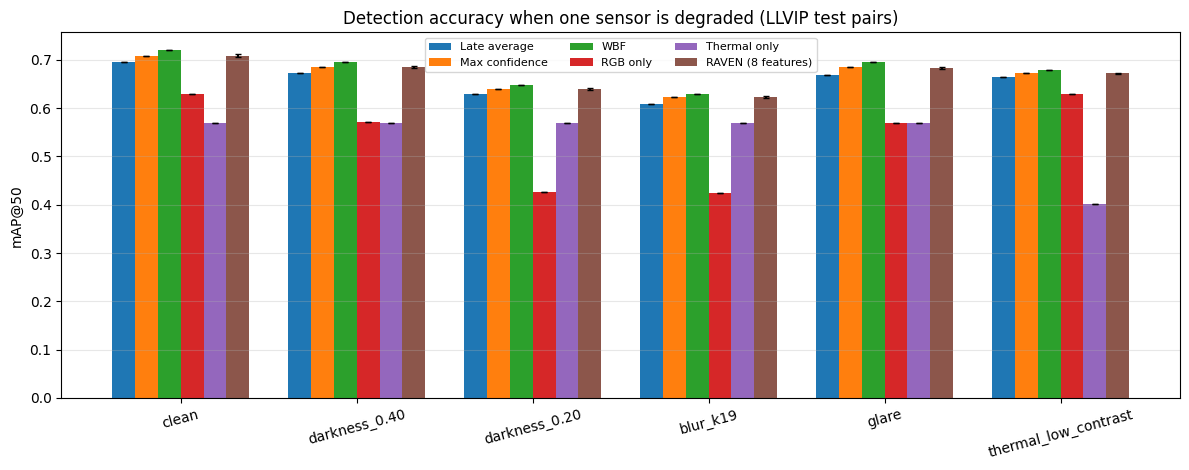

Saved: ['degradation_map50.png', 'degradation_per_run.csv', 'degradation_summary.csv', 'degradation_bootstrap.csv']


In [32]:
# Save tables and a figure.
out_dir = Path(CFG.out_dir)
with open(out_dir / "degradation_summary.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(summary[0].keys())); w.writeheader(); w.writerows(summary)
with open(out_dir / "degradation_per_run.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(deg_rows[0].keys())); w.writeheader(); w.writerows(deg_rows)
with open(out_dir / "degradation_bootstrap.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(boot_rows[0].keys())); w.writeheader(); w.writerows(boot_rows)

show = ["late_average", "max_confidence", "wbf", "rgb_only", "thermal_only", "raven_full_8_features"]
labels = {"late_average": "Late average", "max_confidence": "Max confidence", "wbf": "WBF",
          "rgb_only": "RGB only", "thermal_only": "Thermal only", "raven_full_8_features": "RAVEN (8 features)"}
conds = list(deg_records.keys())
x = np.arange(len(conds)); wd = 0.13
fig, ax = plt.subplots(figsize=(12, 4.8))
for k, pol in enumerate(show):
    vals = [[s for s in summary if s["condition"] == c and s["policy"] == pol][0] for c in conds]
    ax.bar(x + (k - 2.5) * wd, [v["AP50"] for v in vals], wd, yerr=[v["AP50_sd"] for v in vals],
           label=labels[pol], capsize=2)
ax.set_xticks(x); ax.set_xticklabels(conds, rotation=15)
ax.set_ylabel("mAP@50"); ax.set_title("Detection accuracy when one sensor is degraded (LLVIP test pairs)")
ax.grid(axis="y", alpha=0.3); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(out_dir / "degradation_map50.png", dpi=220); plt.show()
print("Saved:", [p.name for p in out_dir.glob("degradation_*")])

## 17. Per-pairing summary (written after the degradation experiment)

Collects the headline numbers of **this** pairing into `pairing_summary.json` so that runs of different pairings, possibly in different sessions, can be compared in §18. Run §1–§16 for the active pairing first.

In [33]:
import math


def _clean(o):
    if isinstance(o, dict):  return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if (math.isnan(float(o)) or math.isinf(float(o))) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o


_full = [r for r in robust_rows if r["ablation"] == "full_8_features"]
_base_ap = results["average_fusion"]["AP50"]
PAIRING_SUMMARY = {
    "pairing": CFG.pairing, "rgb_weights": CFG.rgb_weights, "ir_weights": CFG.ir_weights,
    "detectors": DETECTOR_PROVENANCE,
    "hashes": {"rgb_weights": sha256(DETECTOR_PROVENANCE["rgb"]["checkpoint_path"]) or sha256(CFG.rgb_weights),
               "ir_weights": sha256(DETECTOR_PROVENANCE["ir"]["checkpoint_path"]) or sha256(CFG.ir_weights)},
    "n_test_pairs": len(test_records),
    "candidates": {"train_total": int(len(X_all)), "train": int(len(X_tr)), "val": int(len(X_va)),
                   "test": int(sum(len(r["cands"]) for r in test_records))},
    "clean_benchmark": {p: results[p] for p, _ in POLICIES},
    "raven_full_8_features": {
        "AP50_mean": float(np.mean([r["AP50"] for r in _full])), "AP50_sd": float(np.std([r["AP50"] for r in _full], ddof=1)),
        "delta_vs_late_average_mean": float(np.mean([r["AP50"] - _base_ap for r in _full])),
        "delta_vs_late_average_sd": float(np.std([r["AP50"] - _base_ap for r in _full], ddof=1)),
        "coverage_mean": float(np.mean([r["coverage"] for r in _full])),
        "per_seed": [{"seed": r["seed"], "AP50": r["AP50"], "miss_rate": r["miss_rate"], "FPPI": r["FPPI"],
                      "coverage": r["coverage"], "tau": r["tau_val_95cov"]} for r in _full]},
    "ablations": [{k: r[k] for k in ("ablation", "seed", "AP50", "miss_rate", "FPPI", "coverage")} for r in robust_rows],
    "degradation": summary if isinstance(summary, list) else None,
    "degradation_bootstrap": boot_rows,
    "degradation_pairs": len(recs_clean),
    "degradation_is_dry_run": DEG_MAX_PAIRS is not None,
    "versions": {"python": sys.version.split()[0], "torch": torch.__version__, "ultralytics": ultralytics.__version__},
}
(Path(CFG.out_dir) / "pairing_summary.json").write_text(json.dumps(_clean(PAIRING_SUMMARY), indent=2))
print("Wrote", Path(CFG.out_dir) / "pairing_summary.json")
try:
    from google.colab import files
    shutil.make_archive(f"raven_results_{CFG.pairing}", "zip", CFG.out_dir)
    files.download(f"raven_results_{CFG.pairing}.zip")
except Exception as e:
    print("Download skipped (not in Colab):", e)


Wrote /content/raven_results/v8n_v8n/pairing_summary.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Detector-pairing comparison (run this after two or more pairings have finished)

Reads every `pairing_summary.json` under the shared results folder. The question it answers is **"does the learned arbitration still help when the frozen detectors change?"**: for each pairing, RAVEN's mAP@50 minus each rule-based policy *computed on that pairing's own candidates*. Absolute mAP across pairings mostly reflects detector quality and is not the point.

Caveats to keep in the write-up: the pairings differ in detector generation **and** size (use the optional `y26n_y26n` pairing to separate them); the head is retrained per pairing (3 seeds, same fixed LLVIP train pairs); one dataset; the image-level bootstrap intervals ignore scene clustering.

Completed pairings: ['v8n_v8n']

A. Clean LLVIP test: mAP@50 per policy and RAVEN's advantage over each rule (same pairing, same candidates)
pairing        rgb    thermal  train_cands  test_cands  rgb_only  thermal_only  late_average  max_confidence   wbf  RAVEN_mean  RAVEN_sd  dRAVEN_vs_late_average  dRAVEN_vs_max_confidence  dRAVEN_vs_wbf  coverage
v8n_v8n yolov8n.pt yolov8n.pt          506        7056      0.63        0.5687        0.6961          0.7083 0.721      0.7083    0.0029                  0.0122                       0.0        -0.0127    0.9996

B. Under one-sensor degradation: RAVEN minus the strongest rule-based policy, per pairing
pairing            condition  RAVEN  RAVEN_sd best_rule  best_rule_AP50  dRAVEN_vs_best_rule  dRAVEN_vs_late_average
v8n_v8n             blur_k19 0.6232    0.0016       wbf          0.6298              -0.0065                  0.0145
v8n_v8n                clean 0.7083    0.0029       wbf          0.7210              -0.0127                  

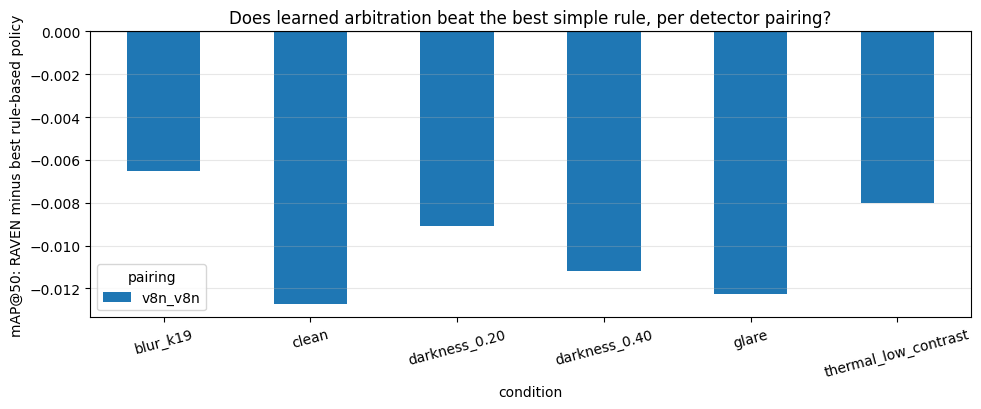

In [35]:
import pandas as pd

BASE_OUT = BASE_OUT if "BASE_OUT" in globals() else str(Path(CFG.out_dir).parent)
files_found = sorted(Path(BASE_OUT).glob("*/pairing_summary.json"))
print("Completed pairings:", [p.parent.name for p in files_found])
SUMS = [json.loads(p.read_text()) for p in files_found]
if not SUMS:
    print("No pairing_summary.json found yet.")
else:
    n_pairs = {s["pairing"]: s["n_test_pairs"] for s in SUMS}
    if len(set(n_pairs.values())) > 1:
        print("WARNING: pairings were evaluated on different numbers of test pairs:", n_pairs)
    if any(s.get("degradation_is_dry_run") for s in SUMS):
        print("WARNING: at least one pairing used a dry-run degradation subset (DEG_MAX_PAIRS).")

    def get(s, cond, pol):
        rows = [r for r in (s.get("degradation") or []) if r["condition"] == cond and r["policy"] == pol]
        return rows[0] if rows else None

    rowsA = []
    for s in SUMS:
        raven = get(s, "clean", "raven_full_8_features")
        row = {"pairing": s["pairing"], "rgb": s["rgb_weights"], "thermal": s["ir_weights"],
               "train_cands": s["candidates"]["train_total"], "test_cands": s["candidates"]["test"]}
        for pol in ("rgb_only", "thermal_only", "late_average", "max_confidence", "wbf"):
            g = get(s, "clean", pol); row[pol] = g["AP50"] if g else np.nan
        row["RAVEN_mean"], row["RAVEN_sd"] = (raven["AP50"], raven["AP50_sd"]) if raven else (np.nan, np.nan)
        for pol in ("late_average", "max_confidence", "wbf"):
            row["dRAVEN_vs_" + pol] = row["RAVEN_mean"] - row[pol]
        row["coverage"] = raven["coverage"] if raven else np.nan
        rowsA.append(row)
    TABLE_A = pd.DataFrame(rowsA)
    pd.set_option("display.width", 220, "display.max_columns", 30)
    print("\nA. Clean LLVIP test: mAP@50 per policy and RAVEN's advantage over each rule (same pairing, same candidates)")
    print(TABLE_A.round(4).to_string(index=False))

    rowsB = []
    for s in SUMS:
        for cond in sorted({r["condition"] for r in (s.get("degradation") or [])}):
            raven = get(s, cond, "raven_full_8_features")
            if not raven: continue
            rules = {p: get(s, cond, p)["AP50"] for p in ("late_average", "max_confidence", "wbf")}
            best = max(rules, key=rules.get)
            rowsB.append({"pairing": s["pairing"], "condition": cond, "RAVEN": raven["AP50"], "RAVEN_sd": raven["AP50_sd"],
                          "best_rule": best, "best_rule_AP50": rules[best], "dRAVEN_vs_best_rule": raven["AP50"] - rules[best],
                          "dRAVEN_vs_late_average": raven["AP50"] - rules["late_average"]})
    TABLE_B = pd.DataFrame(rowsB)
    print("\nB. Under one-sensor degradation: RAVEN minus the strongest rule-based policy, per pairing")
    if len(TABLE_B):
        print(TABLE_B.round(4).to_string(index=False))
        print("\n   dRAVEN_vs_best_rule by condition x pairing")
        print(TABLE_B.pivot(index="condition", columns="pairing", values="dRAVEN_vs_best_rule").round(4).to_string())
    TABLE_A.to_csv(Path(BASE_OUT) / "detector_pairing_clean.csv", index=False)
    TABLE_B.to_csv(Path(BASE_OUT) / "detector_pairing_degradation.csv", index=False)

    if len(TABLE_B):
        piv = TABLE_B.pivot(index="condition", columns="pairing", values="dRAVEN_vs_best_rule")
        ax = piv.plot(kind="bar", figsize=(10, 4.2), rot=15)
        ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("mAP@50: RAVEN minus best rule-based policy")
        ax.set_title("Does learned arbitration beat the best simple rule, per detector pairing?"); ax.grid(axis="y", alpha=0.3)
        plt.tight_layout(); plt.savefig(Path(BASE_OUT) / "detector_pairing_deltas.png", dpi=200); plt.show()
